In [1]:
import pandas as pd

df1 = pd.read_csv("annual-temperature-anomalies.csv")
df2 = pd.read_csv("average-annual-surface-temperature.csv")

for name, df in [
    ("Annual Temperature Anomalies", df1),
    ("Average Annual Surface Temperature", df2)
]:
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("Dimensions:", df.shape)
    print("\nColumns:", df.columns.tolist())
    print("\nData types and missing values:")
    df.info()
    print("\nFirst five rows:")
    display(df.head())


Annual Temperature Anomalies
Dimensions: (18318, 4)

Columns: ['entity', 'code', 'year', 'temperature_anomaly']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 18318 entries, 0 to 18317
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   entity               18318 non-null  str    
 1   code                 16770 non-null  str    
 2   year                 18318 non-null  int64  
 3   temperature_anomaly  18318 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 805.9 KB

First five rows:


,entity,code,year,temperature_anomaly
0,Afghanistan,AFG,1940,-1.202316
1,Afghanistan,AFG,1941,0.794745
2,Afghanistan,AFG,1942,0.355437
3,Afghanistan,AFG,1943,-1.005242
4,Afghanistan,AFG,1944,-0.386346



Average Annual Surface Temperature
Dimensions: (18318, 4)

Columns: ['entity', 'code', 'year', 'temperature_2m']

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 18318 entries, 0 to 18317
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   entity          18318 non-null  str    
 1   code            16770 non-null  str    
 2   year            18318 non-null  int64  
 3   temperature_2m  18318 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 805.9 KB

First five rows:


,entity,code,year,temperature_2m
0,Afghanistan,AFG,1940,11.327695
1,Afghanistan,AFG,1941,13.324756
2,Afghanistan,AFG,1942,12.885448
3,Afghanistan,AFG,1943,11.524769
4,Afghanistan,AFG,1944,12.143665


In [2]:
print("Dataset 1")
print("Number of unique entities:", df1["entity"].nunique())
print("Years covered:", df1["year"].min(), "-", df1["year"].max())

print("\nFirst 20 entities:")
print(sorted(df1["entity"].unique())[:20])

print("\nDataset 2")
print("Number of unique entities:", df2["entity"].nunique())
print("Years covered:", df2["year"].min(), "-", df2["year"].max())

Dataset 1
Number of unique entities: 213
Years covered: 1940 - 2025

First 20 entities:
['Afghanistan', 'Africa (NIAID)', 'Albania', 'Algeria', 'American Samoa', 'Andorra', 'Angola', 'Anguilla', 'Antarctica (NIAID)', 'Antigua and Barbuda', 'Arctic Ocean (NIAID)', 'Argentina', 'Armenia', 'Asia (NIAID)', 'Australia', 'Australia (NIAID)', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain']

Dataset 2
Number of unique entities: 213
Years covered: 1940 - 2025


In [3]:
# Search for global or world-level records
print("Dataset 1 — Global records:")
print(
    df1[df1["entity"].str.contains(
        "world|global", case=False, na=False
    )]["entity"].unique()
)

print("\nDataset 2 — Global records:")
print(
    df2[df2["entity"].str.contains(
        "world|global", case=False, na=False
    )]["entity"].unique()
)

# Check for duplicate entity-year observations
print("\nDuplicate observations:")
print("Dataset 1:", df1.duplicated(["entity", "year"]).sum())
print("Dataset 2:", df2.duplicated(["entity", "year"]).sum())

# Check the latest available observations
print("\nLatest year in Dataset 1:")
display(df1[df1["year"] == df1["year"].max()].head(10))

Dataset 1 — Global records:
<ArrowStringArray>
['World']
Length: 1, dtype: str

Dataset 2 — Global records:
<ArrowStringArray>
['World']
Length: 1, dtype: str

Duplicate observations:
Dataset 1: 0
Dataset 2: 0

Latest year in Dataset 1:


,entity,code,year,temperature_anomaly
85,Afghanistan,AFG,2025,1.274271
171,Africa (NIAID),NaN,2025,0.602335
257,Albania,ALB,2025,1.364645
343,Algeria,DZA,2025,1.040451
429,American Samoa,ASM,2025,0.171732
515,Andorra,AND,2025,1.028368
601,Angola,AGO,2025,0.119362
687,Anguilla,AIA,2025,0.509802
773,Antarctica (NIAID),NaN,2025,1.379681
859,Antigua and Barbuda,ATG,2025,0.465694


In [4]:
# Extract global observations
world_anomalies = df1[df1["entity"] == "World"].copy()
world_temperature = df2[df2["entity"] == "World"].copy()

# Sort by year
world_anomalies = world_anomalies.sort_values("year")
world_temperature = world_temperature.sort_values("year")

# Display the data
print("Global temperature anomalies")
display(world_anomalies.head())

print("\nGlobal average surface temperature")
display(world_temperature.head())

# Check coverage and missing values
print("\nAnomaly dataset")
print("Years:", world_anomalies["year"].min(),
      "to", world_anomalies["year"].max())
print("Missing values:", world_anomalies["temperature_anomaly"].isna().sum())

print("\nSurface temperature dataset")
print("Years:", world_temperature["year"].min(),
      "to", world_temperature["year"].max())
print("Missing values:", world_temperature["temperature_2m"].isna().sum())

Global temperature anomalies


,entity,code,year,temperature_anomaly
17974,World,OWID_WRL,1940,-0.686135
17975,World,OWID_WRL,1941,-0.641774
17976,World,OWID_WRL,1942,-0.732430
17977,World,OWID_WRL,1943,-0.726379
17978,World,OWID_WRL,1944,-0.534997



Global average surface temperature


,entity,code,year,temperature_2m
17974,World,OWID_WRL,1940,13.685313
17975,World,OWID_WRL,1941,13.729674
17976,World,OWID_WRL,1942,13.639018
17977,World,OWID_WRL,1943,13.645069
17978,World,OWID_WRL,1944,13.836452



Anomaly dataset
Years: 1940 to 2025
Missing values: 0

Surface temperature dataset
Years: 1940 to 2025
Missing values: 0


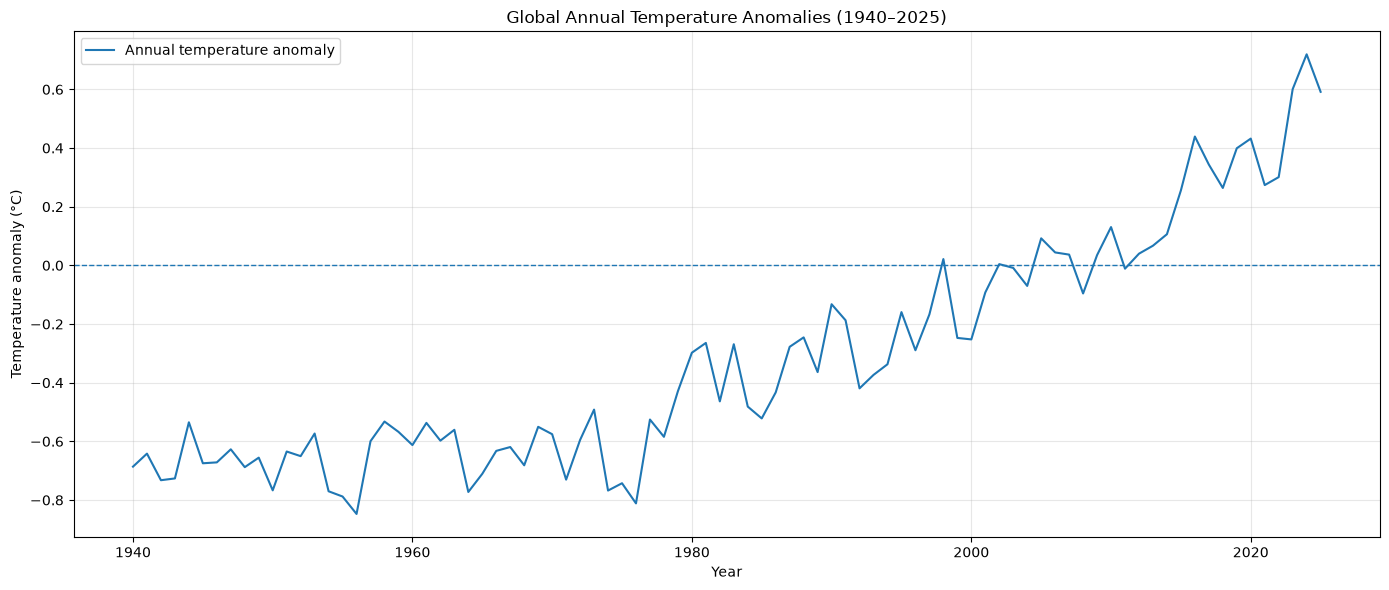

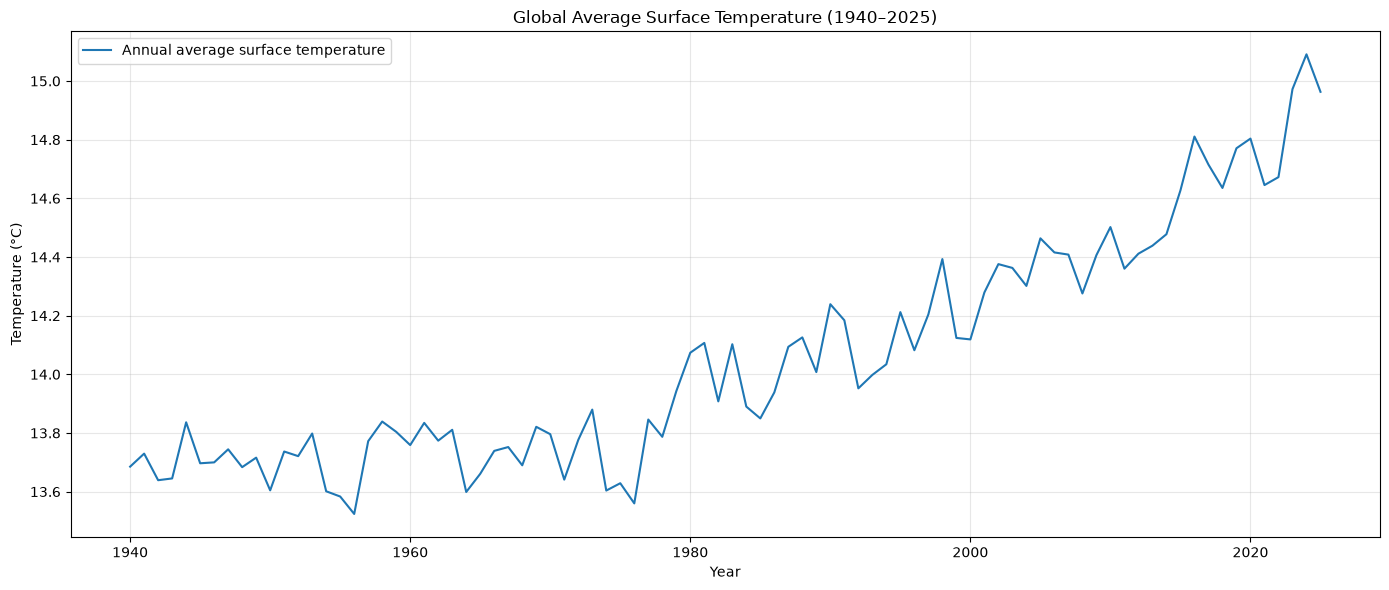

In [5]:
import matplotlib.pyplot as plt

# Sort observations chronologically
world_anomalies = world_anomalies.sort_values("year")
world_temperature = world_temperature.sort_values("year")

# Chart 1: Global temperature anomalies
plt.figure(figsize=(14, 6))

plt.plot(
    world_anomalies["year"],
    world_anomalies["temperature_anomaly"],
    linewidth=1.5,
    label="Annual temperature anomaly"
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Global Annual Temperature Anomalies (1940–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Chart 2: Global average surface temperature
plt.figure(figsize=(14, 6))

plt.plot(
    world_temperature["year"],
    world_temperature["temperature_2m"],
    linewidth=1.5,
    label="Annual average surface temperature"
)

plt.title("Global Average Surface Temperature (1940–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd

# 1. Calculate changes from 1940 to 2025
anomaly_start = world_anomalies.loc[
    world_anomalies["year"] == 1940, "temperature_anomaly"
].iloc[0]

anomaly_end = world_anomalies.loc[
    world_anomalies["year"] == 2025, "temperature_anomaly"
].iloc[0]

temp_start = world_temperature.loc[
    world_temperature["year"] == 1940, "temperature_2m"
].iloc[0]

temp_end = world_temperature.loc[
    world_temperature["year"] == 2025, "temperature_2m"
].iloc[0]

print("CHANGE FROM 1940 TO 2025")
print("-" * 40)
print(f"Anomaly in 1940: {anomaly_start:.3f} °C")
print(f"Anomaly in 2025: {anomaly_end:.3f} °C")
print(f"Change in anomaly: {anomaly_end - anomaly_start:.3f} °C")

print(f"\nSurface temperature in 1940: {temp_start:.3f} °C")
print(f"Surface temperature in 2025: {temp_end:.3f} °C")
print(f"Change in surface temperature: {temp_end - temp_start:.3f} °C")


# 2. Calculate the linear trend
anomaly_slope, anomaly_intercept = np.polyfit(
    world_anomalies["year"],
    world_anomalies["temperature_anomaly"],
    1
)

print("\nLINEAR TREND")
print("-" * 40)
print(f"Anomaly trend: {anomaly_slope * 10:.3f} °C per decade")


# 3. Calculate average anomalies by decade
decade_data = world_anomalies.copy()

decade_data["decade"] = (
    decade_data["year"] // 10
) * 10

decade_averages = decade_data.groupby("decade")[
    "temperature_anomaly"
].mean()

print("\nAVERAGE TEMPERATURE ANOMALY BY DECADE")
display(decade_averages.round(3).to_frame("Mean anomaly (°C)"))

CHANGE FROM 1940 TO 2025
----------------------------------------
Anomaly in 1940: -0.686 °C
Anomaly in 2025: 0.592 °C
Change in anomaly: 1.278 °C

Surface temperature in 1940: 13.685 °C
Surface temperature in 2025: 14.963 °C
Change in surface temperature: 1.278 °C

LINEAR TREND
----------------------------------------
Anomaly trend: 0.142 °C per decade

AVERAGE TEMPERATURE ANOMALY BY DECADE


,Mean anomaly (°C)
decade,
1940,-0.664
1950,-0.673
1960,-0.627
1970,-0.625
1980,-0.362
1990,-0.229
2000,-0.031
2010,0.203
2020,0.486


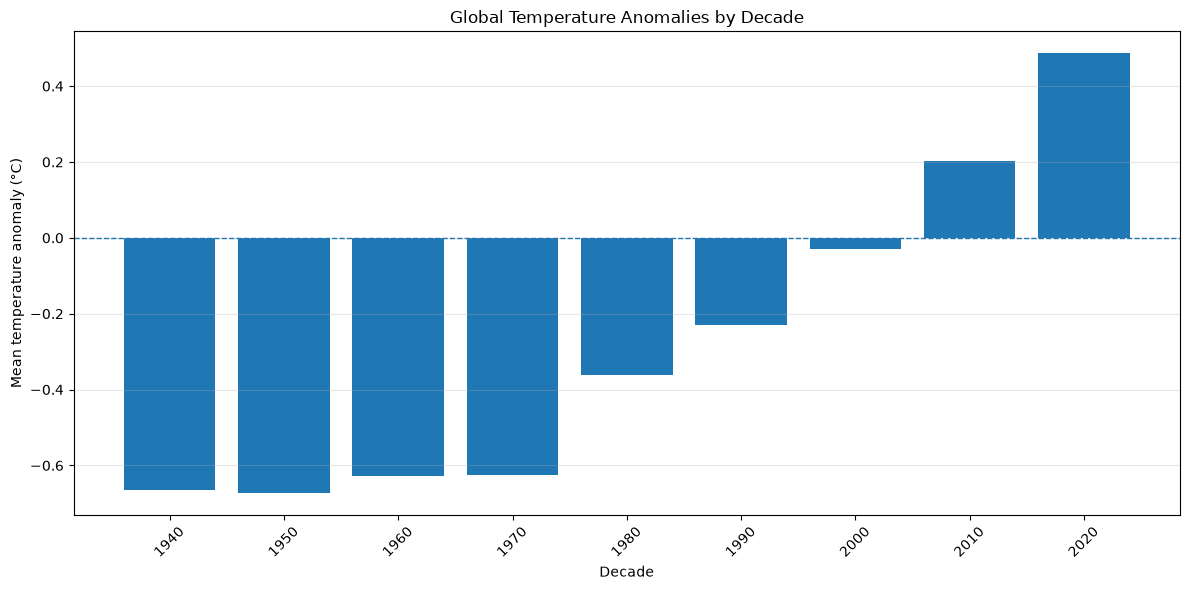

In [8]:
import matplotlib.pyplot as plt

# Calculate average anomaly for each decade
decade_data = world_anomalies.copy()
decade_data["decade"] = (decade_data["year"] // 10) * 10

decade_avg = (
    decade_data.groupby("decade")["temperature_anomaly"]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.bar(
    decade_avg.index.astype(str),
    decade_avg.values
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Global Temperature Anomalies by Decade")
plt.xlabel("Decade")
plt.ylabel("Mean temperature anomaly (°C)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import linregress

# Prepare annual global anomaly data
x = world_anomalies["year"]
y = world_anomalies["temperature_anomaly"]

# Perform linear regression
result = linregress(x, y)

print("STATISTICAL TREND ANALYSIS")
print("-" * 40)
print(f"Slope: {result.slope:.4f} °C per year")
print(f"Trend: {result.slope * 10:.3f} °C per decade")
print(f"R-squared: {result.rvalue**2:.4f}")
print(f"P-value: {result.pvalue:.6g}")
print(f"Correlation coefficient: {result.rvalue:.4f}")

STATISTICAL TREND ANALYSIS
----------------------------------------
Slope: 0.0142 °C per year
Trend: 0.142 °C per decade
R-squared: 0.8261
P-value: 1.18624e-33
Correlation coefficient: 0.9089


In [11]:
# Align the global records by year
comparison = pd.merge(
    world_anomalies[["year", "temperature_anomaly"]],
    world_temperature[["year", "temperature_2m"]],
    on="year",
    how="inner"
)

# Difference between the two series
comparison["difference"] = (
    comparison["temperature_2m"]
    - comparison["temperature_anomaly"]
)

print("Difference between the two series:")
print(comparison["difference"].describe().round(6))

print(
    "\nVariation in the difference:",
    round(comparison["difference"].max()
          - comparison["difference"].min(), 8)
)

Difference between the two series:
count    86.000000
mean     14.371448
std       0.000001
min      14.371447
25%      14.371448
50%      14.371448
75%      14.371448
max      14.371449
Name: difference, dtype: float64

Variation in the difference: 2.22e-06


In [12]:
# Select countries for an initial comparison
countries = ["India", "China", "United States"]

regional_data = df1[
    df1["entity"].isin(countries)
].copy()

# Calculate the linear trend for each country
from scipy.stats import linregress

results = []

for country in countries:
    country_data = regional_data[
        regional_data["entity"] == country
    ].sort_values("year")

    result = linregress(
        country_data["year"],
        country_data["temperature_anomaly"]
    )

    results.append({
        "Country": country,
        "First year": country_data["year"].min(),
        "Last year": country_data["year"].max(),
        "Observations": len(country_data),
        "Trend (°C/decade)": result.slope * 10,
        "R-squared": result.rvalue ** 2
    })

regional_results = pd.DataFrame(results)

display(regional_results.round(4))

,Country,First year,Last year,Observations,Trend (°C/decade),R-squared
0,India,1940,2025,86,0.1335,0.5511
1,China,1940,2025,86,0.1804,0.5382
2,United States,1940,2025,86,0.2385,0.7009


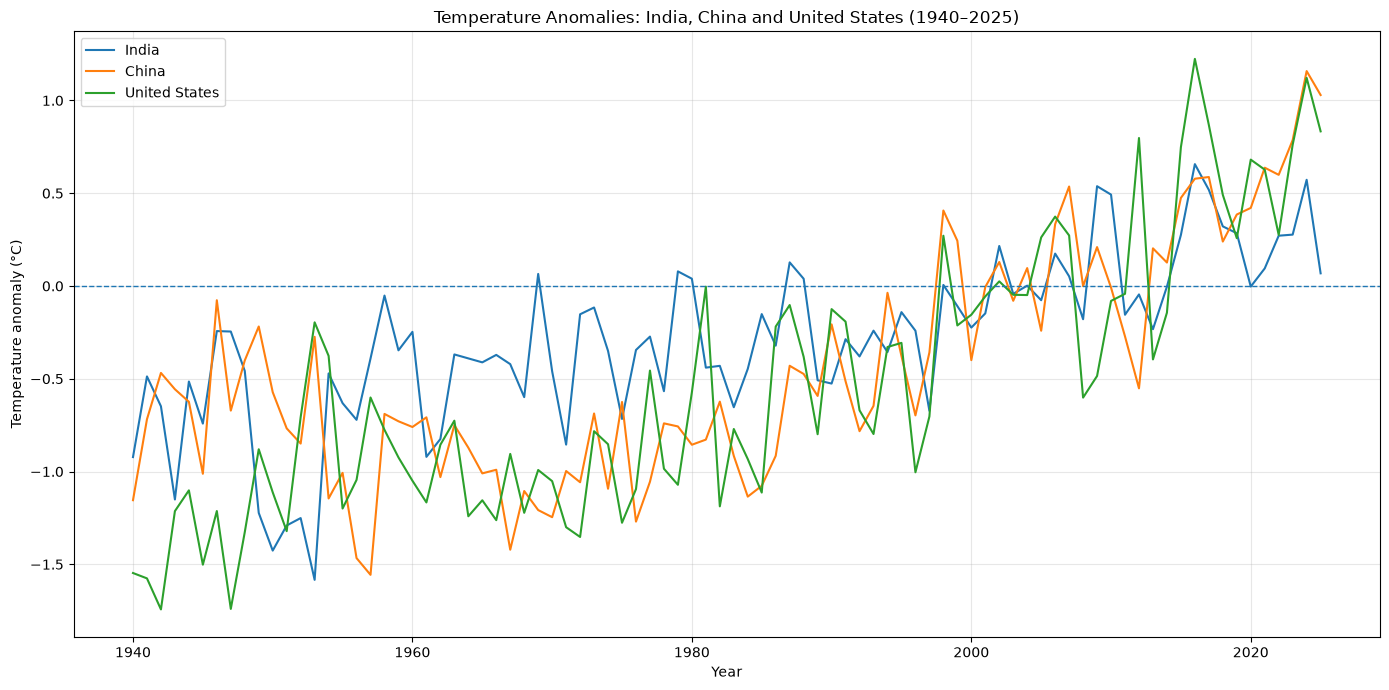

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for country in ["India", "China", "United States"]:
    country_data = regional_data[
        regional_data["entity"] == country
    ].sort_values("year")

    plt.plot(
        country_data["year"],
        country_data["temperature_anomaly"],
        label=country,
        linewidth=1.5
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Temperature Anomalies: India, China and United States (1940–2025)")
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

,Country,1940 anomaly (°C),2025 anomaly (°C),Change 1940–2025 (°C)
0,India,-0.922,0.068,0.990
1,China,-1.154,1.029,2.184
2,United States,-1.547,0.833,2.380


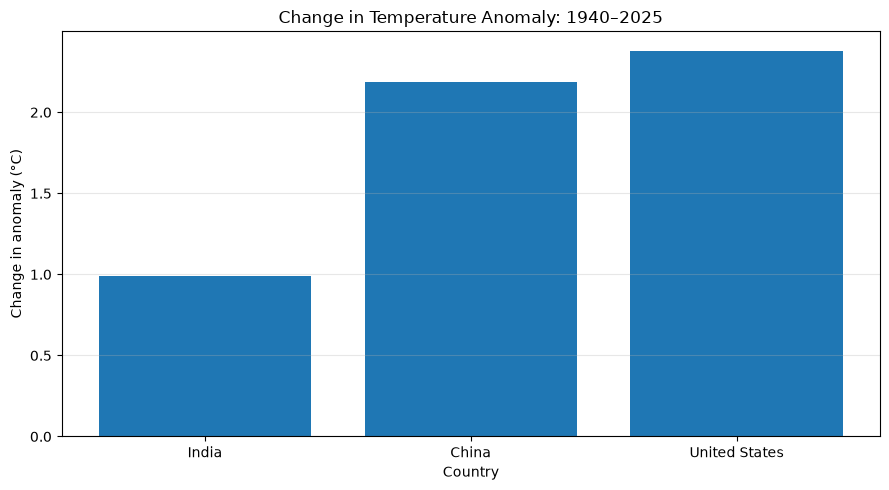

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

countries = ["India", "China", "United States"]
comparison_results = []

for country in countries:
    data = (
        df1[df1["entity"] == country]
        .sort_values("year")
    )

    first = data.iloc[0]
    last = data.iloc[-1]

    comparison_results.append({
        "Country": country,
        "1940 anomaly (°C)": first["temperature_anomaly"],
        "2025 anomaly (°C)": last["temperature_anomaly"],
        "Change 1940–2025 (°C)": (
            last["temperature_anomaly"]
            - first["temperature_anomaly"]
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

# Visualise the change across the observation period
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Country"],
    comparison_df["Change 1940–2025 (°C)"]
)

plt.title("Change in Temperature Anomaly: 1940–2025")
plt.xlabel("Country")
plt.ylabel("Change in anomaly (°C)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

countries = ["India", "China", "United States"]
results = []

for country in countries:
    data = df1[df1["entity"] == country].copy()

    # First ten years: 1940–1949
    early = data[data["year"].between(1940, 1949)]

    # Last ten years: 2016–2025
    recent = data[data["year"].between(2016, 2025)]

    results.append({
        "Country": country,
        "Early period": "1940–1949",
        "Early mean anomaly (°C)": early["temperature_anomaly"].mean(),
        "Recent period": "2016–2025",
        "Recent mean anomaly (°C)": recent["temperature_anomaly"].mean(),
        "Change in mean anomaly (°C)": (
            recent["temperature_anomaly"].mean()
            - early["temperature_anomaly"].mean()
        ),
        "Early observations": early["temperature_anomaly"].count(),
        "Recent observations": recent["temperature_anomaly"].count()
    })

period_comparison = pd.DataFrame(results)

display(period_comparison.round(3))

,Country,Early period,Early mean anomaly (°C),Recent period,Recent mean anomaly (°C),Change in mean anomaly (°C),Early observations,Recent observations
0,India,1940–1949,-0.663,2016–2025,0.306,0.969,10,10
1,China,1940–1949,-0.590,2016–2025,0.642,1.232,10,10
2,United States,1940–1949,-1.384,2016–2025,0.714,2.098,10,10


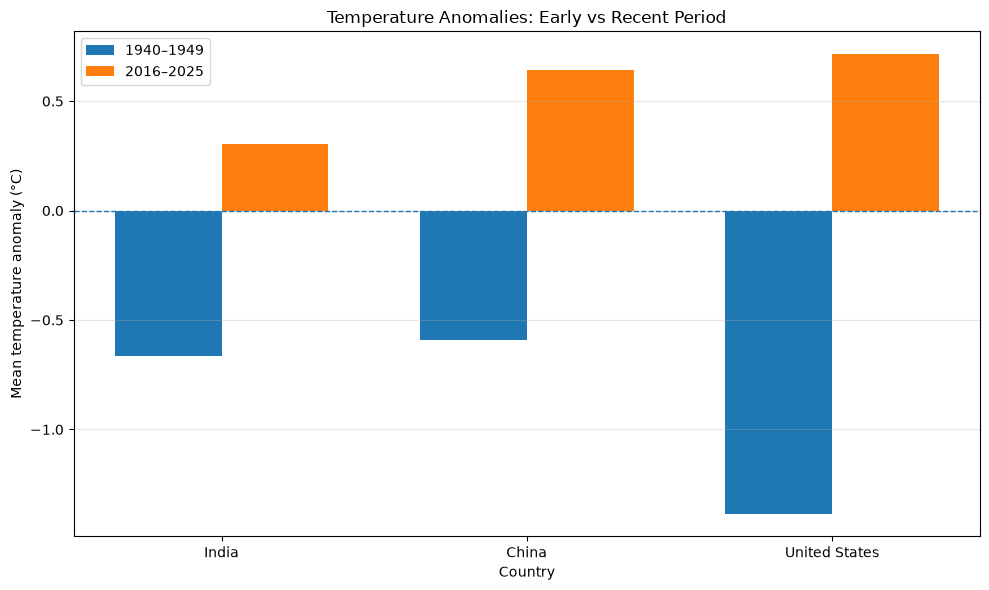

In [16]:
import numpy as np
import matplotlib.pyplot as plt

countries = period_comparison["Country"]

early_values = period_comparison["Early mean anomaly (°C)"]
recent_values = period_comparison["Recent mean anomaly (°C)"]

x = np.arange(len(countries))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    early_values,
    width,
    label="1940–1949"
)

plt.bar(
    x + width / 2,
    recent_values,
    width,
    label="2016–2025"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Temperature Anomalies: Early vs Recent Period")
plt.xlabel("Country")
plt.ylabel("Mean temperature anomaly (°C)")
plt.xticks(x, countries)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
from pathlib import Path

file_path = Path("Full_ensemble_median_and_95pct_range.txt")

print("File exists:", file_path.exists())

with open(file_path, "r", encoding="utf-8") as file:
    for _ in range(30):
        line = file.readline()
        if not line:
            break
        print(line.rstrip())

File exists: True
## This file contains the the median and 95% range (2.5th and 97.5th percentiles) of the full 7000-member ensemble accross all methods of the PAGES2k Consortium 2019 global mean temperature reconstructions.
## We recommend working with the full ensemble provided in the other files in this data compilation for a more robust analysis of GMST.
## The columns in this table are: Year CE, raw instrumental target data, reconstruction ensemble 50th, 2.5th and 97.5th percentiles, 31-year butterworth filtered instrumental target data, 31-year butterworth filtered reconstruction 50th, 2.5th and 97.5th percentiles
## All values are °C wrt 1961-1990 over the April-March annual average.
Year	Cowtan & Way instrumental target	Full ensemble median	Full ensemble 2.5th percentile	Full ensemble 97.5th percentile	Cowtan & Way instrumental target 31-year filtered	31-year filtered full ensemble median	31-year filtered full ensemble 2.5th percentile	31-year filtered full ensemble 97.5th perc

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the downloaded file
file_path = Path("Full_ensemble_median_and_95pct_range.txt")

# Check that the file exists
if not file_path.exists():
    raise FileNotFoundError(
        f"File not found: {file_path.resolve()}"
    )

# Read the tab-separated data, ignoring metadata lines beginning with ##
paleo = pd.read_csv(
    file_path,
    sep="\t",
    comment="#",
    na_values=["NA"]
)

# Clean column names
paleo.columns = paleo.columns.str.strip()

print("Dataset dimensions:", paleo.shape)
print("\nColumn names:")
print(paleo.columns.tolist())

print("\nFirst five observations:")
display(paleo.head())

print("\nLast five observations:")
display(paleo.tail())

print("\nMissing values:")
display(paleo.isnull().sum().to_frame("Missing values"))

print("\nYear range:")
print(paleo["Year"].min(), "to", paleo["Year"].max())

Dataset dimensions: (2017, 9)

Column names:
['Year', 'Cowtan & Way instrumental target', 'Full ensemble median', 'Full ensemble 2.5th percentile', 'Full ensemble 97.5th percentile', 'Cowtan & Way instrumental target 31-year filtered', '31-year filtered full ensemble median', '31-year filtered full ensemble 2.5th percentile', '31-year filtered full ensemble 97.5th percentile']

First five observations:


,Year,Cowtan & Way instrumental target,Full ensemble median,Full ensemble 2.5th percentile,Full ensemble 97.5th percentile,Cowtan & Way instrumental target 31-year filtered,31-year filtered full ensemble median,31-year filtered full ensemble 2.5th percentile,31-year filtered full ensemble 97.5th percentile
0,1,NaN,-0.3690,-0.7515,0.0176,NaN,NaN,NaN,NaN
1,2,NaN,-0.3548,-0.7328,0.0292,NaN,NaN,NaN,NaN
2,3,NaN,-0.3120,-0.7308,0.0821,NaN,NaN,NaN,NaN
3,4,NaN,-0.3041,-0.6638,0.1169,NaN,NaN,NaN,NaN
4,5,NaN,-0.3034,-0.6808,0.0913,NaN,NaN,NaN,NaN



Last five observations:


,Year,Cowtan & Way instrumental target,Full ensemble median,Full ensemble 2.5th percentile,Full ensemble 97.5th percentile,Cowtan & Way instrumental target 31-year filtered,31-year filtered full ensemble median,31-year filtered full ensemble 2.5th percentile,31-year filtered full ensemble 97.5th percentile
2012,2013,0.5552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013,2014,0.6543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014,2015,0.8532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015,2016,0.8148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016,2017,0.6671,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,Missing values
Year,0
Cowtan & Way instrumental target,1849
Full ensemble median,17
Full ensemble 2.5th percentile,17
Full ensemble 97.5th percentile,17
Cowtan & Way instrumental target 31-year filtered,1879
31-year filtered full ensemble median,47
31-year filtered full ensemble 2.5th percentile,47
31-year filtered full ensemble 97.5th percentile,47



Year range:
1 to 2017


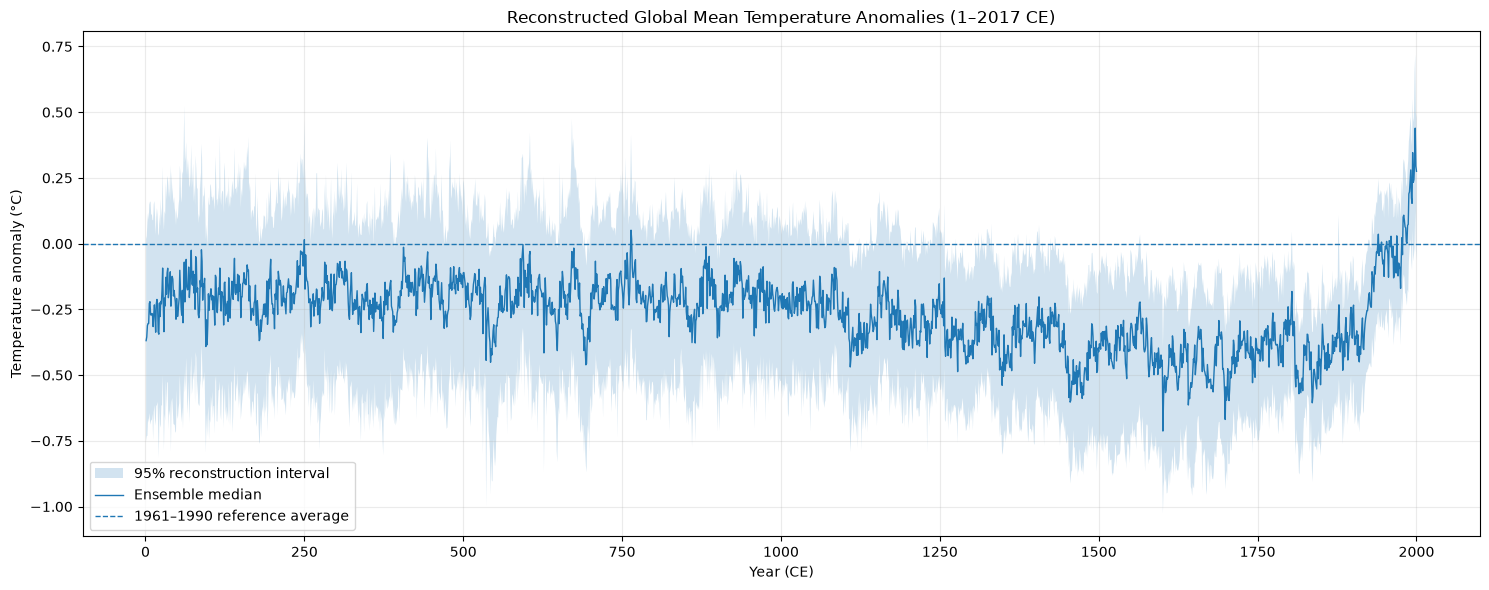

Years covered: 1 to 2000
Valid reconstruction observations: 2000


In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Keep only rows with complete reconstruction estimates
paleo_valid = paleo.dropna(
    subset=[
        "Full ensemble median",
        "Full ensemble 2.5th percentile",
        "Full ensemble 97.5th percentile"
    ]
).copy()

# Sort chronologically
paleo_valid = paleo_valid.sort_values("Year")

years = paleo_valid["Year"]
median = paleo_valid["Full ensemble median"]
lower = paleo_valid["Full ensemble 2.5th percentile"]
upper = paleo_valid["Full ensemble 97.5th percentile"]

plt.figure(figsize=(15, 6))

# Uncertainty interval
plt.fill_between(
    years,
    lower,
    upper,
    alpha=0.2,
    label="95% reconstruction interval"
)

# Median reconstruction
plt.plot(
    years,
    median,
    linewidth=1,
    label="Ensemble median"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    label="1961–1990 reference average"
)

plt.title("Reconstructed Global Mean Temperature Anomalies (1–2017 CE)")
plt.xlabel("Year (CE)")
plt.ylabel("Temperature anomaly (°C)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Years covered:", years.min(), "to", years.max())
print("Valid reconstruction observations:", len(paleo_valid))

Observation 1: Temperatures fluctuated over the first millennium
From approximately 1 CE to 1000 CE, the reconstructed median generally remains below the 1961–1990 reference average, although there are substantial year-to-year fluctuations.
Interpretation: The reconstruction suggests variability around a generally negative temperature anomaly during much of this period. Negative anomalies do not mean that the planet was freezing; they mean temperatures were below the specified reference average.

Observation 2: The reconstructed median becomes lower during parts of the second millennium
Between approximately 1200 and 1900 CE, the median appears to remain relatively low, with some pronounced fluctuations.
This is consistent with the broad pattern of cooler conditions during parts of the preindustrial period, but we should avoid assigning specific historical climate events from this graph alone.

Observation 3: The reconstruction rises sharply near its end
The median rises substantially around the late nineteenth and early twentieth centuries.
However, we need to investigate this section before interpreting it. Your file contains both a reconstruction and a separate instrumental temperature series, and the reconstruction has missing values near its end. The apparent rise may reflect the final reconstructed estimates, so we should inspect the underlying data and compare the series carefully.

Observation 4: The uncertainty band is substantial
The shaded area represents the 2.5th to 97.5th percentiles of the reconstruction ensemble.
It shows that the historical temperature estimates have uncertainty. This is important when comparing reconstructed temperatures across centuries.

In [20]:
# Find the final year with a valid reconstruction median
valid_median = paleo.dropna(
    subset=["Full ensemble median"]
)

print(
    "Reconstruction begins:",
    valid_median["Year"].min()
)

print(
    "Reconstruction ends:",
    valid_median["Year"].max()
)

print(
    "\nFinal 20 reconstruction observations:"
)

display(
    valid_median[
        [
            "Year",
            "Full ensemble median",
            "Full ensemble 2.5th percentile",
            "Full ensemble 97.5th percentile"
        ]
    ].tail(20)
)

Reconstruction begins: 1
Reconstruction ends: 2000

Final 20 reconstruction observations:


,Year,Full ensemble median,Full ensemble 2.5th percentile,Full ensemble 97.5th percentile
1980,1981,0.0879,-0.1299,0.3099
1981,1982,0.0640,-0.1878,0.2839
1982,1983,0.0602,-0.1912,0.2700
1983,1984,0.0071,-0.2145,0.2264
1984,1985,0.0011,-0.2349,0.2160
1985,1986,0.0697,-0.1742,0.2828
1986,1987,0.0731,-0.1869,0.3170
1987,1988,0.1892,-0.0680,0.3881
1988,1989,0.1978,-0.0269,0.4138
1989,1990,0.2359,0.0001,0.4600


In [21]:
# Extract years where both reconstruction and instrumental data exist

overlap = paleo.dropna(
    subset=[
        "Full ensemble median",
        "Cowtan & Way instrumental target"
    ]
).copy()

print("First overlapping year:", overlap["Year"].min())
print("Last overlapping year:", overlap["Year"].max())
print("Number of overlapping observations:", len(overlap))

display(
    overlap[
        [
            "Year",
            "Full ensemble median",
            "Cowtan & Way instrumental target"
        ]
    ].head(10)
)

First overlapping year: 1850
Last overlapping year: 2000
Number of overlapping observations: 151


,Year,Full ensemble median,Cowtan & Way instrumental target
1849,1850,-0.4575,-0.3898
1850,1851,-0.4036,-0.2612
1851,1852,-0.3063,-0.2256
1852,1853,-0.3508,-0.3349
1853,1854,-0.4011,-0.2441
1854,1855,-0.3896,-0.2971
1855,1856,-0.4766,-0.4321
1856,1857,-0.4620,-0.4832
1857,1858,-0.4149,-0.4247
1858,1859,-0.4818,-0.4103


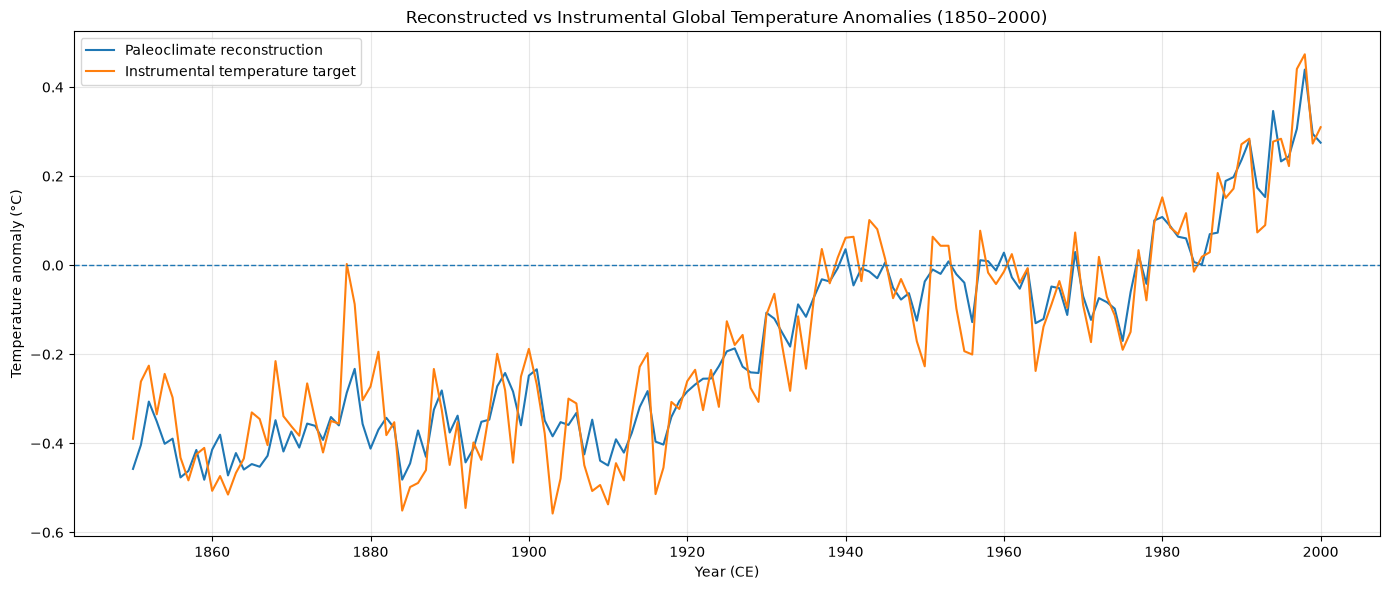

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    overlap["Year"],
    overlap["Full ensemble median"],
    label="Paleoclimate reconstruction",
    linewidth=1.5
)

plt.plot(
    overlap["Year"],
    overlap["Cowtan & Way instrumental target"],
    label="Instrumental temperature target",
    linewidth=1.5
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title(
    "Reconstructed vs Instrumental Global Temperature Anomalies (1850–2000)"
)
plt.xlabel("Year (CE)")
plt.ylabel("Temperature anomaly (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

observed = overlap["Cowtan & Way instrumental target"]
reconstructed = overlap["Full ensemble median"]

mae = mean_absolute_error(observed, reconstructed)
rmse = np.sqrt(mean_squared_error(observed, reconstructed))
correlation = observed.corr(reconstructed)

print("COMPARISON RESULTS (1850–2000)")
print("-" * 40)
print(f"Overlapping observations: {len(overlap)}")
print(f"Mean absolute difference: {mae:.3f} °C")
print(f"Root mean squared difference: {rmse:.3f} °C")
print(f"Correlation coefficient: {correlation:.3f}")

COMPARISON RESULTS (1850–2000)
----------------------------------------
Overlapping observations: 151
Mean absolute difference: 0.059 °C
Root mean squared difference: 0.075 °C
Correlation coefficient: 0.944


In [24]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

# Check the overlapping observations
print("Overlapping years:", len(overlap))
print("Year range:", overlap["Year"].min(), "to", overlap["Year"].max())

# Compare reconstructed and instrumental temperatures
reconstruction = overlap["Full ensemble median"]
instrumental = overlap["Cowtan & Way instrumental target"]

# Calculate agreement statistics
mae = mean_absolute_error(instrumental, reconstruction)
rmse = np.sqrt(mean_squared_error(instrumental, reconstruction))
correlation, p_value = pearsonr(instrumental, reconstruction)

print("\nRECONSTRUCTION VALIDATION")
print("-" * 40)
print(f"Mean Absolute Error: {mae:.3f} °C")
print(f"Root Mean Squared Error: {rmse:.3f} °C")
print(f"Pearson Correlation: {correlation:.3f}")
print(f"P-value: {p_value:.6g}")


Overlapping years: 151
Year range: 1850 to 2000

RECONSTRUCTION VALIDATION
----------------------------------------
Mean Absolute Error: 0.059 °C
Root Mean Squared Error: 0.075 °C
Pearson Correlation: 0.944
P-value: 1.36061e-73


In [26]:

import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals: reconstruction minus instrumental target
overlap = overlap.copy()

overlap["residual"] = (
    overlap["Full ensemble median"]
    - overlap["Cowtan & Way instrumental target"]
)

print("RESIDUAL ANALYSIS")
print("-" * 40)
print(f"Mean residual: {overlap['residual'].mean():.4f} °C")
print(f"Residual standard deviation: {overlap['residual'].std():.4f} °C")
print(f"Largest positive residual: {overlap['residual'].max():.4f} °C")
print(f"Largest negative residual: {overlap['residual'].min():.4f} °C")

print("\nYears with the five largest absolute residuals:")

display(
    overlap.assign(
        absolute_residual=overlap["residual"].abs()
    )
    .nlargest(5, "absolute_residual")[
        ["Year", "Full ensemble median",
         "Cowtan & Way instrumental target", "residual"]
    ]
    .round(4)
)


RESIDUAL ANALYSIS
----------------------------------------
Mean residual: -0.0029 °C
Residual standard deviation: 0.0756 °C
Largest positive residual: 0.1905 °C
Largest negative residual: -0.2891 °C

Years with the five largest absolute residuals:


,Year,Full ensemble median,Cowtan & Way instrumental target,residual
1876,1877,-0.2864,0.0027,-0.2891
1949,1950,-0.0366,-0.2271,0.1905
1880,1881,-0.3693,-0.1944,-0.1749
1902,1903,-0.3843,-0.5577,0.1734
1907,1908,-0.3469,-0.5071,0.1602


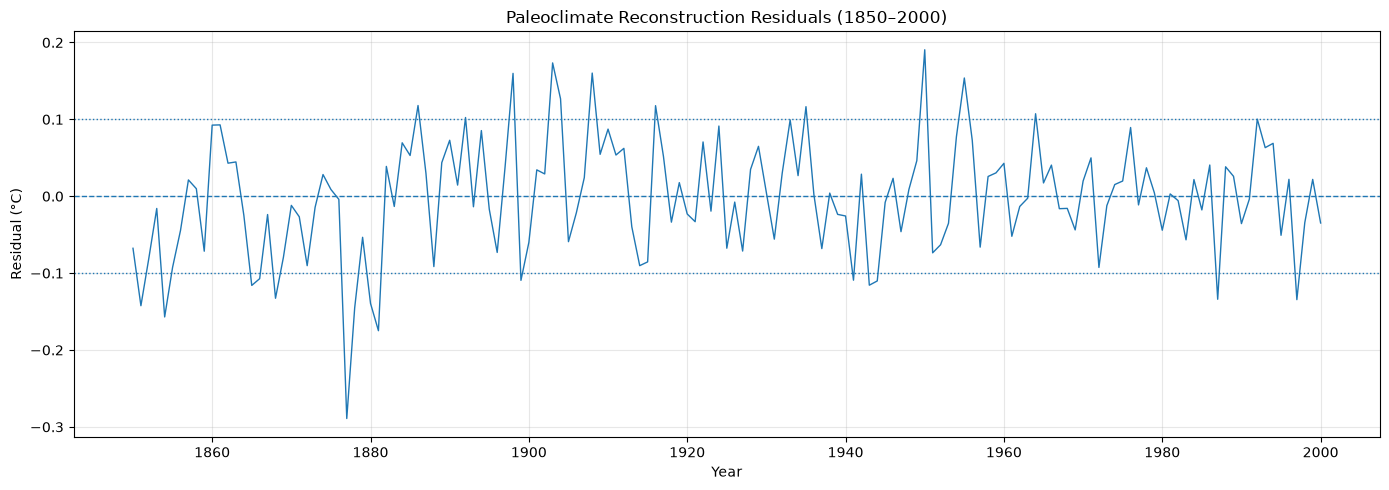

In [27]:
plt.figure(figsize=(14, 5))

plt.plot(
    overlap["Year"],
    overlap["residual"],
    linewidth=1
)

plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(0.1, linestyle=":", linewidth=1)
plt.axhline(-0.1, linestyle=":", linewidth=1)

plt.title("Paleoclimate Reconstruction Residuals (1850–2000)")
plt.xlabel("Year")
plt.ylabel("Residual (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Compare residuals across historical periods

overlap = overlap.copy()

overlap["period"] = pd.cut(
    overlap["Year"],
    bins=[1849, 1900, 1950, 2000],
    labels=["1850–1900", "1901–1950", "1951–2000"],
    include_lowest=True
)

period_analysis = overlap.groupby(
    "period", observed=False
)["residual"].agg(
    ["count", "mean", "std", "min", "max"]
)

period_analysis = period_analysis.rename(columns={
    "count": "Number of years",
    "mean": "Mean residual (°C)",
    "std": "Residual standard deviation (°C)",
    "min": "Minimum residual (°C)",
    "max": "Maximum residual (°C)"
})

display(period_analysis.round(4))

,Number of years,Mean residual (°C),Residual standard deviation (°C),Minimum residual (°C),Maximum residual (°C)
period,,,,,
1850–1900,51,-0.0258,0.0876,-0.2891,0.1598
1901–1950,50,0.0144,0.0735,-0.1157,0.1905
1951–2000,50,0.0032,0.0581,-0.1345,0.1538


Finding 1: The average bias was small.
All three periods have mean residuals between −0.026°C and +0.014°C. This suggests that the reconstruction did not consistently overestimate or underestimate the instrumental target by a large amount on average.

Finding 2: Residual variability declined across the periods.
The residual standard deviation decreased from 0.0876°C in 1850–1900 to 0.0581°C in 1951–2000.
This indicates that the differences between the reconstruction and instrumental target were less variable in the later period. However, we cannot conclude that the reconstruction itself necessarily became more accurate: the number and quality of available proxy records, the reconstruction methodology, and the calibration process may all influence this pattern.

Finding 3: The largest discrepancies occurred in the earlier periods.
The largest negative residual was −0.2891°C in 1877, while the largest positive residual was +0.1905°C in 1950.
These are individual-year differences, not estimates of long-term temperature trends.

<Figure size 1000x600 with 0 Axes>

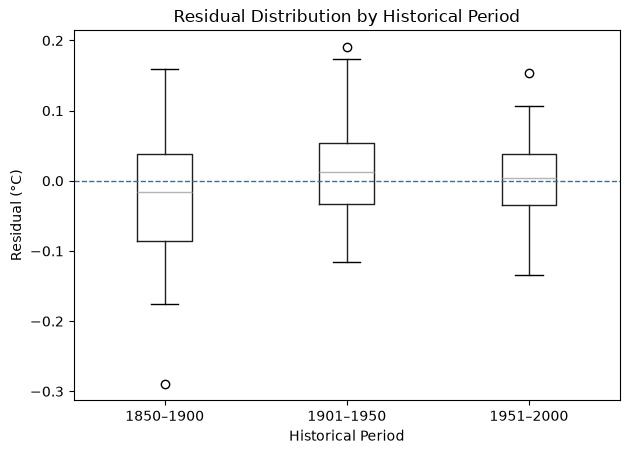

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

overlap.boxplot(
    column="residual",
    by="period",
    grid=False
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Residual Distribution by Historical Period")
plt.suptitle("")
plt.xlabel("Historical Period")
plt.ylabel("Residual (°C)")

plt.tight_layout()
plt.show()

In [31]:
# Prepare the modern global temperature data

modern_global = world_temperature[
    world_temperature["entity"] == "World"
].copy()

modern_global = modern_global.sort_values("year")

# Keep the years covered by the modern dataset
modern_global = modern_global[
    modern_global["year"].between(1940, 2025)
]

# Prepare the paleoclimate reconstruction
paleo_plot = paleo.dropna(
    subset=["Full ensemble median"]
).copy()

paleo_plot = paleo_plot.sort_values("Year")

# Display the ranges to verify both datasets

print("MODERN GLOBAL TEMPERATURE DATA")
print("First year:", modern_global["year"].min())
print("Last year:", modern_global["year"].max())
print("Number of observations:", len(modern_global))

print("\nPAGES2k PALEOCLIMATE RECONSTRUCTION")
print("First year:", paleo_plot["Year"].min())
print("Last year:", paleo_plot["Year"].max())
print("Number of observations:", len(paleo_plot))

MODERN GLOBAL TEMPERATURE DATA
First year: 1940
Last year: 2025
Number of observations: 86

PAGES2k PALEOCLIMATE RECONSTRUCTION
First year: 1
Last year: 2000
Number of observations: 2000


In [35]:
modern_global = df1[
    df1["entity"] == "World"
].copy()

modern_global = modern_global[
    modern_global["year"].between(1940, 2025)
].sort_values("year")

print("Modern global temperature anomalies")
print("Observations:", len(modern_global))
print("Years:", modern_global["year"].min(), "to",
      modern_global["year"].max())

display(modern_global.head())

Modern global temperature anomalies
Observations: 86
Years: 1940 to 2025


,entity,code,year,temperature_anomaly
17974,World,OWID_WRL,1940,-0.686135
17975,World,OWID_WRL,1941,-0.641774
17976,World,OWID_WRL,1942,-0.732430
17977,World,OWID_WRL,1943,-0.726379
17978,World,OWID_WRL,1944,-0.534997


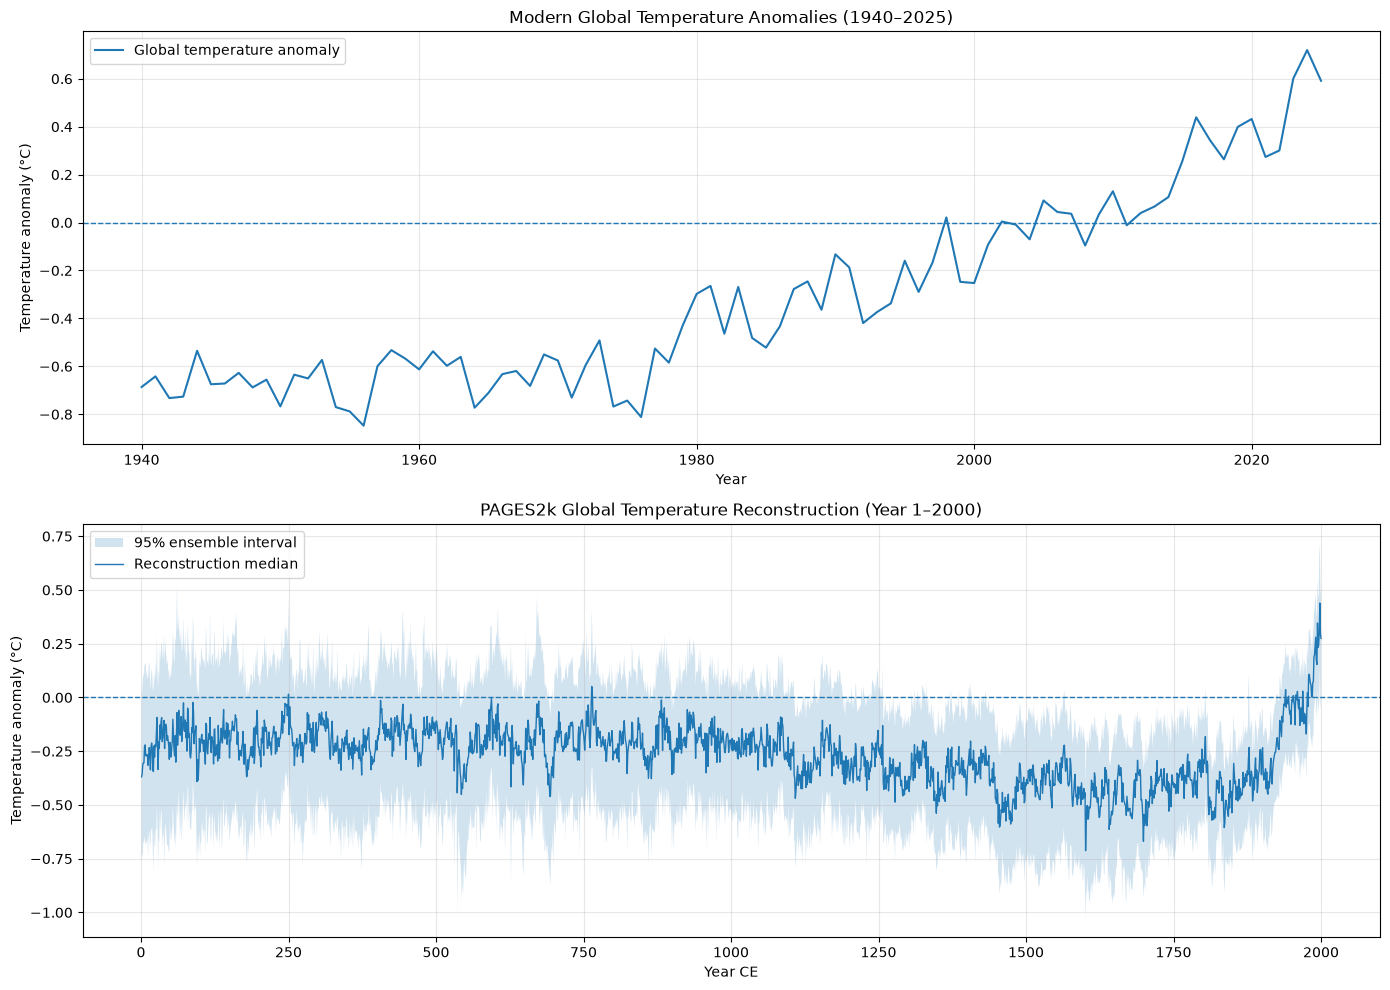

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Panel 1: Modern global temperature anomalies
axes[0].plot(
    modern_global["year"],
    modern_global["temperature_anomaly"],
    linewidth=1.5,
    label="Global temperature anomaly"
)

axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_title("Modern Global Temperature Anomalies (1940–2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Temperature anomaly (°C)")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Panel 2: PAGES2k paleoclimate reconstruction
axes[1].fill_between(
    paleo_plot["Year"],
    paleo_plot["Full ensemble 2.5th percentile"],
    paleo_plot["Full ensemble 97.5th percentile"],
    alpha=0.2,
    label="95% ensemble interval"
)

axes[1].plot(
    paleo_plot["Year"],
    paleo_plot["Full ensemble median"],
    linewidth=1,
    label="Reconstruction median"
)

axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("PAGES2k Global Temperature Reconstruction (Year 1–2000)")
axes[1].set_xlabel("Year CE")
axes[1].set_ylabel("Temperature anomaly (°C)")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [37]:
# Prepare the 31-year filtered paleoclimate reconstruction

filtered_paleo = paleo.dropna(
    subset=["31-year filtered full ensemble median"]
).copy()

filtered_paleo = filtered_paleo.sort_values("Year")

print("31-Year Filtered Paleoclimate Reconstruction")
print("First year:", filtered_paleo["Year"].min())
print("Last year:", filtered_paleo["Year"].max())
print("Number of observations:", len(filtered_paleo))

31-Year Filtered Paleoclimate Reconstruction
First year: 16
Last year: 1985
Number of observations: 1970


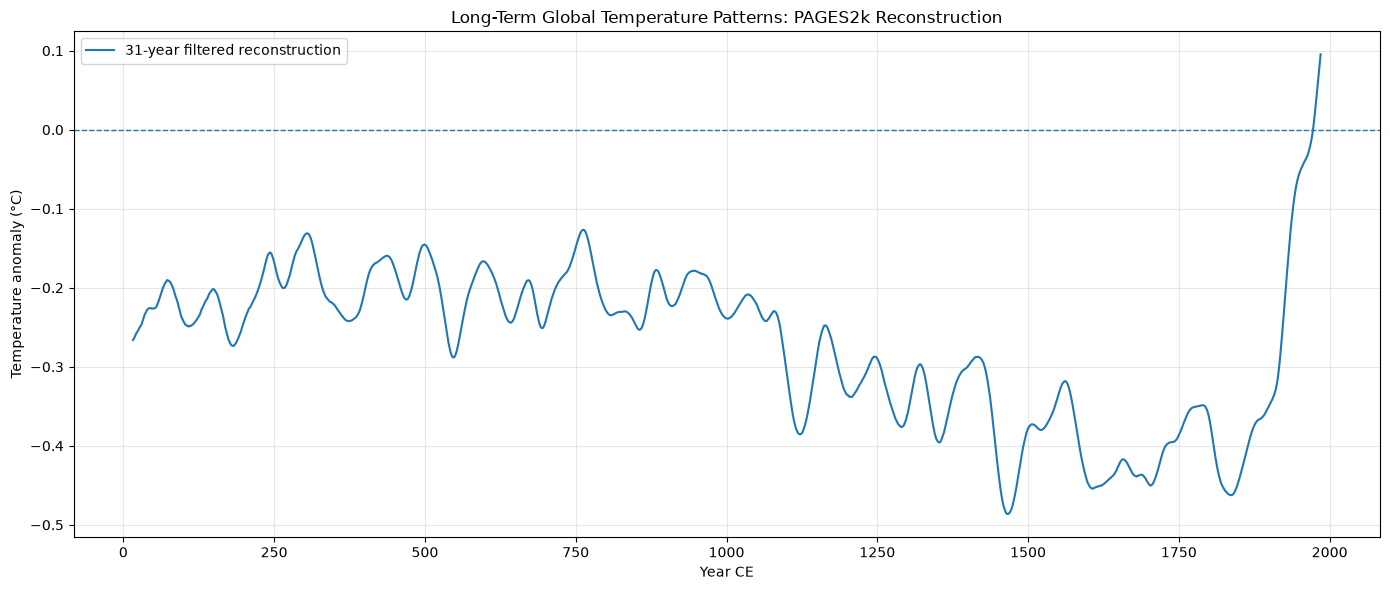

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    filtered_paleo["Year"],
    filtered_paleo["31-year filtered full ensemble median"],
    linewidth=1.5,
    label="31-year filtered reconstruction"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Long-Term Global Temperature Patterns: PAGES2k Reconstruction")
plt.xlabel("Year CE")
plt.ylabel("Temperature anomaly (°C)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

A. Year 1–1000: Relatively stable reconstructed temperatures
The smoothed reconstruction fluctuates around approximately −0.15°C to −0.29°C.
There are variations, but no sustained rise comparable to the sharp increase at the end of the series.

B. Approximately 1000–1850: Cooler reconstructed intervals
The series generally becomes more negative, although the pattern is not uniform.
The lowest point appears around the fifteenth century, at approximately −0.49°C.
These are patterns in the reconstructed global temperature series; they should not be interpreted as evidence that every region experienced the same temperature changes.

C. Approximately 1850–1985: A sharp increase near the endpoint
The reconstruction rises sharply toward the end of the curve, reaching approximately +0.10°C.

In [39]:
# Inspect the final 20 observations of the filtered reconstruction

display(
    filtered_paleo[
        ["Year", "31-year filtered full ensemble median"]
    ]
    .tail(20)
    .round(4)
)

,Year,31-year filtered full ensemble median
1965,1966,-0.0257
1966,1967,-0.0228
1967,1968,-0.0195
1968,1969,-0.0158
1969,1970,-0.0117
1970,1971,-0.0072
1971,1972,-0.0018
1972,1973,0.0039
1973,1974,0.0102
1974,1975,0.0172


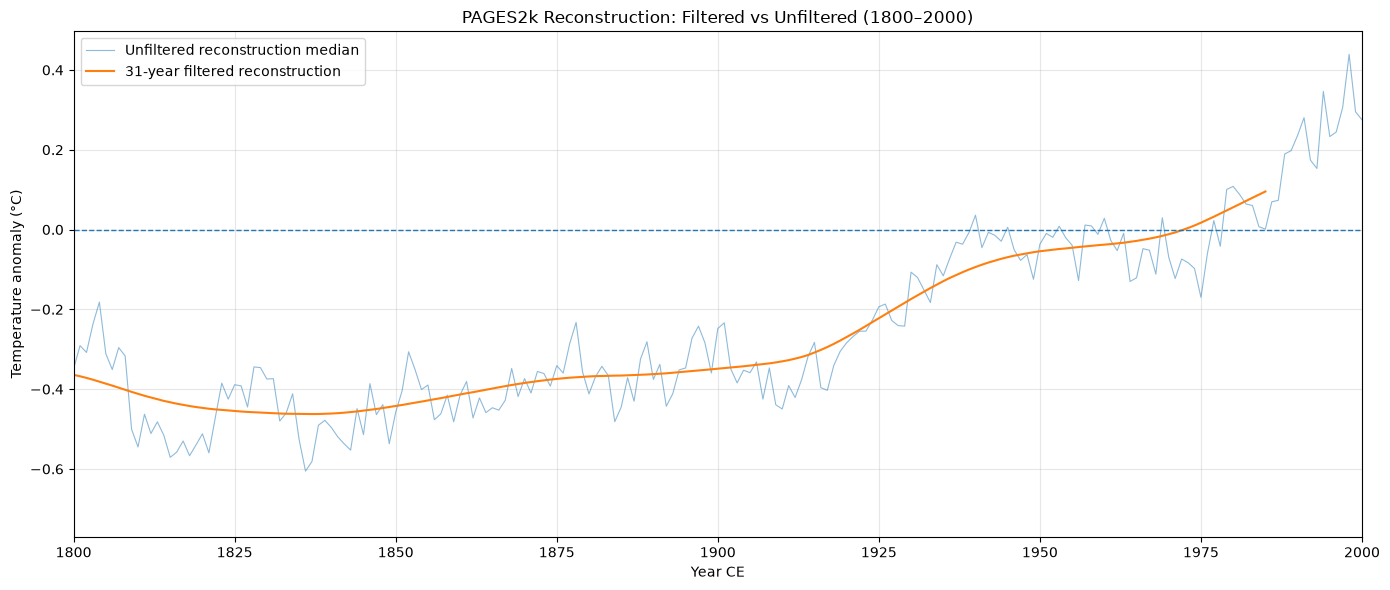

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    paleo["Year"],
    paleo["Full ensemble median"],
    alpha=0.5,
    linewidth=0.8,
    label="Unfiltered reconstruction median"
)

plt.plot(
    paleo["Year"],
    paleo["31-year filtered full ensemble median"],
    linewidth=1.5,
    label="31-year filtered reconstruction"
)

plt.xlim(1800, 2000)
plt.axhline(0, linestyle="--", linewidth=1)

plt.title("PAGES2k Reconstruction: Filtered vs Unfiltered (1800–2000)")
plt.xlabel("Year CE")
plt.ylabel("Temperature anomaly (°C)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

A. The filter preserves the broad trend
The blue line represents the annual reconstruction median, while the orange line represents the 31-year filtered median.
The orange line suppresses short-term fluctuations and reveals longer-term changes more clearly.
    
B. The nineteenth century shows relatively cool reconstructed temperatures
The filtered series reaches a low point in the early nineteenth century, then generally rises toward the late nineteenth and early twentieth centuries.

C. The twentieth century shows a substantial upward trend
The filtered reconstruction rises from approximately −0.35°C around 1900 to positive anomalies toward the end of its available record.

In [41]:
# Compare reconstructed temperatures across historical periods

periods = {
    "1850–1899": (1850, 1899),
    "1900–1949": (1900, 1949),
    "1950–1979": (1950, 1979),
    "1980–2000": (1980, 2000)
}

results = []

for period, (start, end) in periods.items():
    subset = paleo[
        paleo["Year"].between(start, end)
    ]["Full ensemble median"].dropna()

    results.append({
        "Period": period,
        "Observations": len(subset),
        "Mean reconstructed anomaly (°C)": subset.mean(),
        "Minimum (°C)": subset.min(),
        "Maximum (°C)": subset.max()
    })

period_summary = pd.DataFrame(results)

display(period_summary.round(4))

,Period,Observations,Mean reconstructed anomaly (°C),Minimum (°C),Maximum (°C)
0,1850–1899,50,-0.3820,-0.4818,-0.2328
1,1900–1949,50,-0.2163,-0.4498,0.0359
2,1950–1979,30,-0.0442,-0.1701,0.1006
3,1980–2000,21,0.1829,0.0011,0.4392


In [42]:
# Calculate changes between consecutive historical-period averages

period_summary["Change from previous period (°C)"] = (
    period_summary["Mean reconstructed anomaly (°C)"].diff()
)

display(
    period_summary[
        [
            "Period",
            "Mean reconstructed anomaly (°C)",
            "Change from previous period (°C)"
        ]
    ].round(4)
)

,Period,Mean reconstructed anomaly (°C),Change from previous period (°C)
0,1850–1899,-0.3820,NaN
1,1900–1949,-0.2163,0.1658
2,1950–1979,-0.0442,0.1721
3,1980–2000,0.1829,0.2271


# Global Temperature Analysis: Modern Observations and Paleoclimate Reconstruction

## 1. Research Objective

This project examines global temperature patterns using modern observations and historical paleoclimate reconstructions. The objective is to investigate long-term temperature trends, historical variability, and uncertainty.

Two datasets are used:

- Modern global temperature anomalies from Our World in Data (OWID), covering 1940–2025.
- Historical global temperature reconstructions from the PAGES2k Consortium 2019 dataset, covering Year 1–2000.

## 2. Modern Global Temperature Analysis (1940–2025)

The modern global temperature anomaly series shows a substantial upward trend.

Key findings:

- Initial anomaly in 1940: -0.686 degrees C.
- Final anomaly in 2025: +0.592 degrees C.
- Change between endpoints: +1.278 degrees C.
- Estimated linear trend: +0.142 degrees C per decade.
- Coefficient of determination (R-squared): 0.8261.

The positive trend indicates that global temperature anomalies increased over the period examined. Although annual fluctuations occur, the overall direction is upward.

These values are temperature anomalies relative to the OWID dataset's reference baseline, not absolute global temperatures.

## 3. Historical Paleoclimate Reconstruction

The PAGES2k dataset provides reconstructed global temperature estimates and an uncertainty interval derived from a reconstruction ensemble.

The reconstruction median varies over the approximately two-thousand-year record. The series shows cooler reconstructed anomalies during portions of the second millennium, followed by an increase toward the end of the available record.

A 31-year filtered reconstruction is also available. Filtering reduces short-term fluctuations and makes longer-term patterns easier to examine.

The uncertainty interval is defined by the 2.5th and 97.5th percentiles of the reconstruction ensemble. It represents uncertainty in the reconstructed estimates.

## 4. Comparison with the Instrumental Target

The reconstruction median was compared with the Cowtan and Way instrumental target over the overlapping period of 1850–2000.

Key results:

- Mean absolute error (MAE): 0.059 degrees C.
- Root mean squared error (RMSE): 0.075 degrees C.
- Pearson correlation: 0.944.
- Mean residual: -0.0029 degrees C.
- Residual standard deviation: 0.0756 degrees C.

Residuals were calculated by subtracting the instrumental target from the reconstruction median.

The small mean residual indicates little average signed difference between the two series. The MAE and RMSE describe the magnitude of their differences, while the correlation measures the strength of their linear association.

The results indicate substantial agreement during the overlapping period. However, this should not be treated as independent validation because instrumental observations may have contributed to the reconstruction's calibration.

## 5. Residual Analysis Across Historical Periods

The residual analysis produced the following results:

- 1850–1900: Mean residual of -0.0258 degrees C; standard deviation of 0.0876 degrees C.
- 1901–1950: Mean residual of +0.0144 degrees C; standard deviation of 0.0735 degrees C.
- 1951–2000: Mean residual of +0.0032 degrees C; standard deviation of 0.0581 degrees C.

The mean residual remained relatively close to zero across all three periods.

Residual variability declined across the periods. However, this pattern alone does not prove that the reconstruction became more accurate over time.

The box plot also identified unusually large residuals. These observations may warrant further investigation but should not automatically be classified as errors.

## 6. Historical Period Comparisons

The mean reconstructed temperature anomalies were calculated for four historical periods:

- 1850–1899: -0.3820 degrees C.
- 1900–1949: -0.2163 degrees C.
- 1950–1979: -0.0442 degrees C.
- 1980–2000: +0.1829 degrees C.

The mean anomaly increased successively across these periods.

The difference between the mean anomalies for 1850–1899 and 1980–2000 was approximately +0.5649 degrees C.

This value represents a difference between two period averages. It is not an annual warming rate or a direct estimate of total warming since the nineteenth century.

## 7. Key Findings

1. Modern global temperature anomalies show a substantial upward trend between 1940 and 2025.
2. The PAGES2k reconstruction documents historical variability in reconstructed global temperatures over approximately two millennia.
3. The reconstruction and instrumental target show strong correlation during their overlapping period, subject to limitations associated with calibration and data dependence.
4. Residual variability differs across historical periods and is lower in the later periods examined.
5. Mean reconstructed anomalies increase across the four selected periods from the nineteenth century to the late twentieth century.

## 8. Limitations

- The modern and paleoclimate datasets use different reference periods, averaging conventions, and methodologies. Their raw anomaly values should not be compared directly without harmonization.
- The reconstruction and instrumental target may not be independent because instrumental observations can contribute to calibration.
- The filtered reconstruction covers fewer years than the unfiltered reconstruction in the downloaded file. Endpoint behavior requires cautious interpretation.
- Regression significance estimates may be affected by temporal autocorrelation.
- Temperature records alone cannot establish the causes of climate change or demonstrate ecological responses.
- Historical period comparisons are descriptive and do not independently identify the causes of temperature changes.

## 9. Conclusion

The analysis identifies an upward trend in modern global temperature anomalies and documents long-term variability in the PAGES2k historical reconstruction.

The reconstruction also shows substantial agreement with the instrumental target during the overlapping period, although this comparison has limitations related to calibration and data dependence.

These findings provide a foundation for further research into the relationship between climate variability and Earth-system history.

A subsequent stage could integrate independent ecological, paleontological, fossil-occurrence, or vegetation records to investigate whether documented biological changes coincide with particular climate patterns. Such comparisons would require careful consideration of chronology, geographic coverage, and uncertainty.

In [43]:
import numpy as np
from scipy.stats import linregress

# Use the global temperature anomaly data
modern_global = df1[
    (df1["entity"] == "World") &
    (df1["year"].between(1940, 2025))
].copy()

modern_global = modern_global.dropna(
    subset=["year", "temperature_anomaly"]
).sort_values("year")

# Calculate the linear trend
result = linregress(
    modern_global["year"],
    modern_global["temperature_anomaly"]
)

print("Number of observations:", len(modern_global))
print(f"Temperature trend: {result.slope * 10:.4f} °C per decade")
print(f"R-squared: {result.rvalue**2:.4f}")
print(f"Correlation: {result.rvalue:.4f}")
print(f"P-value: {result.pvalue:.6e}")

Number of observations: 86
Temperature trend: 0.1421 °C per decade
R-squared: 0.8261
Correlation: 0.9089
P-value: 1.186242e-33


In [44]:
# Define the two periods
early_period = modern_global[
    modern_global["year"].between(1940, 1979)
]

recent_period = modern_global[
    modern_global["year"].between(1980, 2025)
]

# Calculate descriptive statistics
early_mean = early_period["temperature_anomaly"].mean()
recent_mean = recent_period["temperature_anomaly"].mean()

print("EARLY PERIOD: 1940–1979")
print(f"Observations: {len(early_period)}")
print(f"Mean anomaly: {early_mean:.3f} °C")

print("\nRECENT PERIOD: 1980–2025")
print(f"Observations: {len(recent_period)}")
print(f"Mean anomaly: {recent_mean:.3f} °C")

print("\nCOMPARISON")
print(f"Difference in means: {recent_mean - early_mean:+.3f} °C")

EARLY PERIOD: 1940–1979
Observations: 40
Mean anomaly: -0.647 °C

RECENT PERIOD: 1980–2025
Observations: 46
Mean anomaly: -0.027 °C

COMPARISON
Difference in means: +0.620 °C


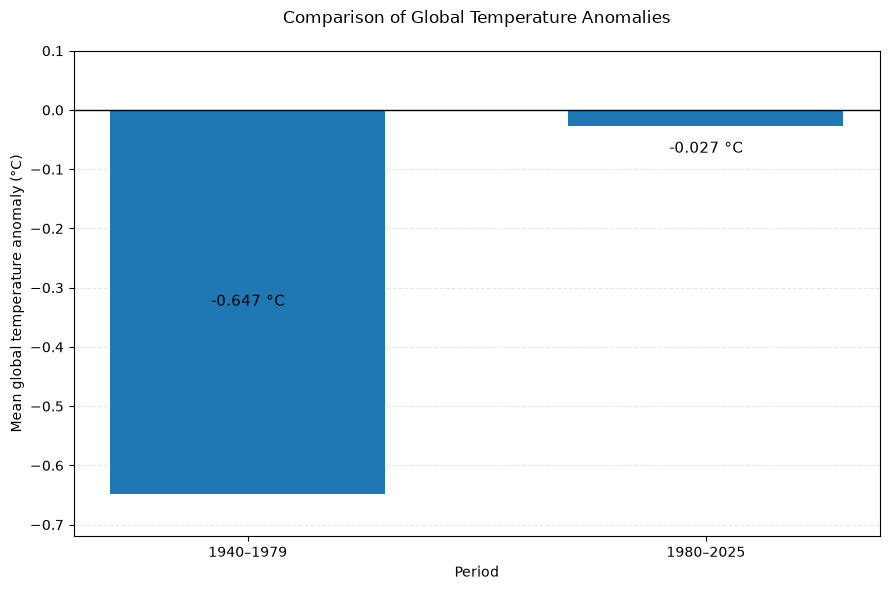

In [47]:
import matplotlib.pyplot as plt

periods = ["1940–1979", "1980–2025"]
means = [early_mean, recent_mean]

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(periods, means, width=0.6)

# Reference line at zero anomaly
ax.axhline(0, linewidth=1, color="black")

ax.set_ylabel("Mean global temperature anomaly (°C)")
ax.set_xlabel("Period")
ax.set_title(
    "Comparison of Global Temperature Anomalies",
    pad=20
)

# Add labels without overlapping the title
for bar, value in zip(bars, means):
    if value < -0.1:
        label_y = value / 2
        va = "center"
    else:
        label_y = value - 0.025
        va = "top"

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        label_y,
        f"{value:+.3f} °C",
        ha="center",
        va=va,
        fontsize=11
    )

# Add space above zero and below the lowest bar
ax.set_ylim(-0.72, 0.10)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [48]:
# Calculate mean global temperature anomaly by decade

decadal_data = modern_global.copy()

decadal_data["Decade"] = (
    decadal_data["year"] // 10
) * 10

decadal_summary = (
    decadal_data.groupby("Decade")["temperature_anomaly"]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

decadal_summary.columns = [
    "Decade",
    "Mean Anomaly (°C)",
    "Minimum (°C)",
    "Maximum (°C)",
    "Observations"
]

print(decadal_summary.round(3).to_string(index=False))

 Decade  Mean Anomaly (°C)  Minimum (°C)  Maximum (°C)  Observations
   1940             -0.664        -0.732        -0.535            10
   1950             -0.673        -0.847        -0.532            10
   1960             -0.627        -0.773        -0.537            10
   1970             -0.625        -0.811        -0.429            10
   1980             -0.362        -0.522        -0.246            10
   1990             -0.229        -0.419         0.022            10
   2000             -0.031        -0.252         0.092            10
   2010              0.203        -0.011         0.439            10
   2020              0.486         0.274         0.720             6


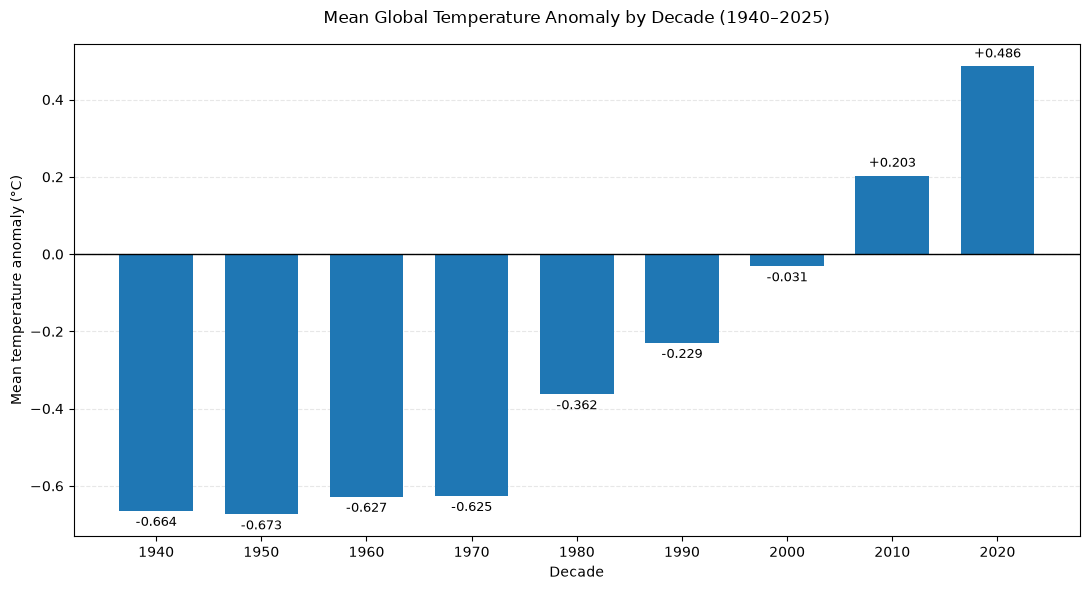

In [49]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    decadal_summary["Decade"].astype(str),
    decadal_summary["Mean Anomaly (°C)"],
    width=0.7
)

# Reference line at zero
ax.axhline(0, color="black", linewidth=1)

# Add labels
for bar, value in zip(
    bars,
    decadal_summary["Mean Anomaly (°C)"]
):
    if value >= 0:
        y_position = value + 0.015
        vertical_alignment = "bottom"
    else:
        y_position = value - 0.015
        vertical_alignment = "top"

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        y_position,
        f"{value:+.3f}",
        ha="center",
        va=vertical_alignment,
        fontsize=9
    )

ax.set_title(
    "Mean Global Temperature Anomaly by Decade (1940–2025)",
    pad=15
)
ax.set_xlabel("Decade")
ax.set_ylabel("Mean temperature anomaly (°C)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [50]:
from scipy.stats import linregress

# First period: 1940–1979
period_1 = modern_global[
    modern_global["year"].between(1940, 1979)
]

trend_1 = linregress(
    period_1["year"],
    period_1["temperature_anomaly"]
)

# Second period: 1980–2025
period_2 = modern_global[
    modern_global["year"].between(1980, 2025)
]

trend_2 = linregress(
    period_2["year"],
    period_2["temperature_anomaly"]
)

print("PERIOD 1: 1940–1979")
print(f"Trend: {trend_1.slope * 10:+.4f} °C per decade")
print(f"R-squared: {trend_1.rvalue**2:.4f}")

print("\nPERIOD 2: 1980–2025")
print(f"Trend: {trend_2.slope * 10:+.4f} °C per decade")
print(f"R-squared: {trend_2.rvalue**2:.4f}")

print("\nCOMPARISON")
print(
    f"Difference in estimated slopes: "
    f"{(trend_2.slope - trend_1.slope) * 10:+.4f} °C per decade"
)

PERIOD 1: 1940–1979
Trend: +0.0184 °C per decade
R-squared: 0.0501

PERIOD 2: 1980–2025
Trend: +0.2133 °C per decade
R-squared: 0.8437

COMPARISON
Difference in estimated slopes: +0.1950 °C per decade


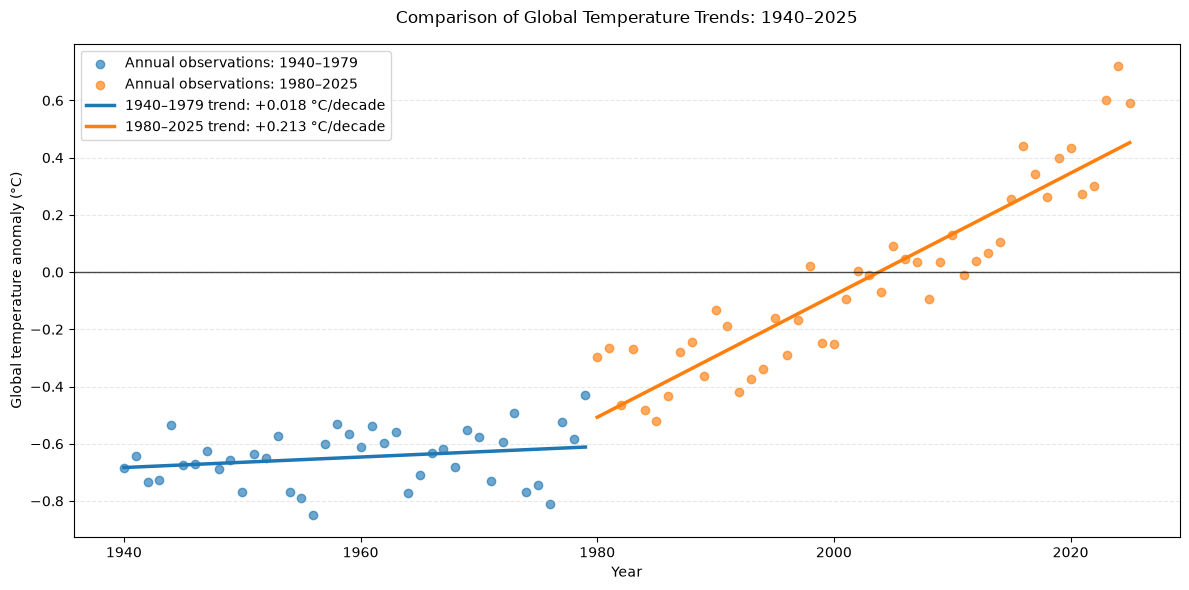

In [51]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6))

# Plot annual observations
ax.scatter(
    period_1["year"],
    period_1["temperature_anomaly"],
    alpha=0.65,
    label="Annual observations: 1940–1979"
)

ax.scatter(
    period_2["year"],
    period_2["temperature_anomaly"],
    alpha=0.65,
    label="Annual observations: 1980–2025"
)

# Plot fitted trend lines
x1 = np.linspace(1940, 1979, 100)
y1 = trend_1.slope * x1 + trend_1.intercept

x2 = np.linspace(1980, 2025, 100)
y2 = trend_2.slope * x2 + trend_2.intercept

ax.plot(
    x1, y1,
    linewidth=2.5,
    label=f"1940–1979 trend: {trend_1.slope * 10:+.3f} °C/decade"
)

ax.plot(
    x2, y2,
    linewidth=2.5,
    label=f"1980–2025 trend: {trend_2.slope * 10:+.3f} °C/decade"
)

ax.axhline(0, color="black", linewidth=1, alpha=0.7)

ax.set_title(
    "Comparison of Global Temperature Trends: 1940–2025",
    pad=15
)
ax.set_xlabel("Year")
ax.set_ylabel("Global temperature anomaly (°C)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [52]:
import statsmodels.formula.api as smf

# Prepare data for the regression
trend_data = modern_global.copy()

trend_data["Period"] = np.where(
    trend_data["year"] < 1980,
    "Earlier",
    "Later"
)

# Center the year variable to improve interpretability
trend_data["Year_centered"] = trend_data["year"] - 1980

# Regression with an interaction between period and year
model = smf.ols(
    "temperature_anomaly ~ Year_centered * C(Period)",
    data=trend_data
).fit()

print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     temperature_anomaly   R-squared:                       0.921
Model:                             OLS   Adj. R-squared:                  0.918
Method:                  Least Squares   F-statistic:                     318.4
Date:                 Sat, 24 Oct 2026   Prob (F-statistic):           4.56e-45
Time:                         19:56:08   Log-Likelihood:                 68.487
No. Observations:                   86   AIC:                            -129.0
Df Residuals:                       82   BIC:                            -119.2
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [53]:
# Recalculate standard errors allowing for heteroskedasticity
# and short-range autocorrelation.

model_hac = model.get_robustcov_results(
    cov_type="HAC",
    maxlags=4
)

# Display the robust regression results
print(model_hac.summary())

                             OLS Regression Results                            
Dep. Variable:     temperature_anomaly   R-squared:                       0.921
Model:                             OLS   Adj. R-squared:                  0.918
Method:                  Least Squares   F-statistic:                     227.1
Date:                 Sat, 24 Oct 2026   Prob (F-statistic):           1.30e-39
Time:                         19:56:33   Log-Likelihood:                 68.487
No. Observations:                   86   AIC:                            -129.0
Df Residuals:                       82   BIC:                            -119.2
Df Model:                            3                                         
Covariance Type:                   HAC                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [54]:
# Sensitivity analysis using different HAC lag choices

lag_choices = [1, 2, 4, 8, 10]

results = []

for lag in lag_choices:
    robust_model = model.get_robustcov_results(
        cov_type="HAC",
        maxlags=lag
    )

    # The interaction is the fourth coefficient
    interaction_index = list(model.params.index).index(
        "Year_centered:C(Period)[T.Later]"
    )

    results.append({
        "HAC lags": lag,
        "Interaction coefficient": robust_model.params[interaction_index],
        "Robust standard error": robust_model.bse[interaction_index],
        "t-statistic": robust_model.tvalues[interaction_index],
        "p-value": robust_model.pvalues[interaction_index]
    })

hac_sensitivity = pd.DataFrame(results)

print(hac_sensitivity.round(6).to_string(index=False))

 HAC lags  Interaction coefficient  Robust standard error  t-statistic  p-value
        1                 0.019496               0.002423     8.045545      0.0
        2                 0.019496               0.002566     7.597190      0.0
        4                 0.019496               0.002608     7.474595      0.0
        8                 0.019496               0.002394     8.143625      0.0
       10                 0.019496               0.002396     8.137281      0.0


In [55]:
import numpy as np
import pandas as pd

# Prepare the data
change_data = modern_global[
    ["year", "temperature_anomaly"]
].dropna().sort_values("year").copy()

years = change_data["year"].to_numpy()
temps = change_data["temperature_anomaly"].to_numpy()

# Fit a single linear trend for comparison
single_fit = np.polyfit(years, temps, 1)
single_pred = np.polyval(single_fit, years)
single_rss = np.sum((temps - single_pred) ** 2)

# Search candidate change points
candidate_years = range(1950, 2016)
results = []

for cp in candidate_years:
    before = years <= cp
    after = years > cp

    # Require at least 10 observations in each segment
    if before.sum() < 10 or after.sum() < 10:
        continue

    fit_before = np.polyfit(years[before], temps[before], 1)
    fit_after = np.polyfit(years[after], temps[after], 1)

    pred_before = np.polyval(fit_before, years[before])
    pred_after = np.polyval(fit_after, years[after])

    rss = (
        np.sum((temps[before] - pred_before) ** 2)
        + np.sum((temps[after] - pred_after) ** 2)
    )

    results.append({
        "Candidate year": cp,
        "RSS": rss,
        "RSS reduction (%)": 100 * (single_rss - rss) / single_rss,
        "Earlier trend (°C/decade)": fit_before[0] * 10,
        "Later trend (°C/decade)": fit_after[0] * 10
    })

change_results = pd.DataFrame(results)

best_change = change_results.loc[
    change_results["RSS"].idxmin()
]

print("BEST CANDIDATE CHANGE POINT")
print(best_change.to_string())

print("\nTOP 10 CANDIDATE YEARS")
print(
    change_results.nsmallest(10, "RSS")
    .round(4)
    .to_string(index=False)
)

BEST CANDIDATE CHANGE POINT
Candidate year               1976.000000
RSS                             0.982802
RSS reduction (%)              56.380356
Earlier trend (°C/decade)       0.003846
Later trend (°C/decade)         0.210762

TOP 10 CANDIDATE YEARS
 Candidate year    RSS  RSS reduction (%)  Earlier trend (°C/decade)  Later trend (°C/decade)
           1976 0.9828            56.3804                     0.0038                   0.2108
           1973 0.9901            56.0558                     0.0247                   0.2213
           1977 0.9954            55.8201                     0.0089                   0.2118
           1978 0.9963            55.7830                     0.0110                   0.2107
           1974 1.0018            55.5362                     0.0169                   0.2188
           1975 1.0019            55.5331                     0.0115                   0.2161
           1970 1.0064            55.3335                     0.0229                 

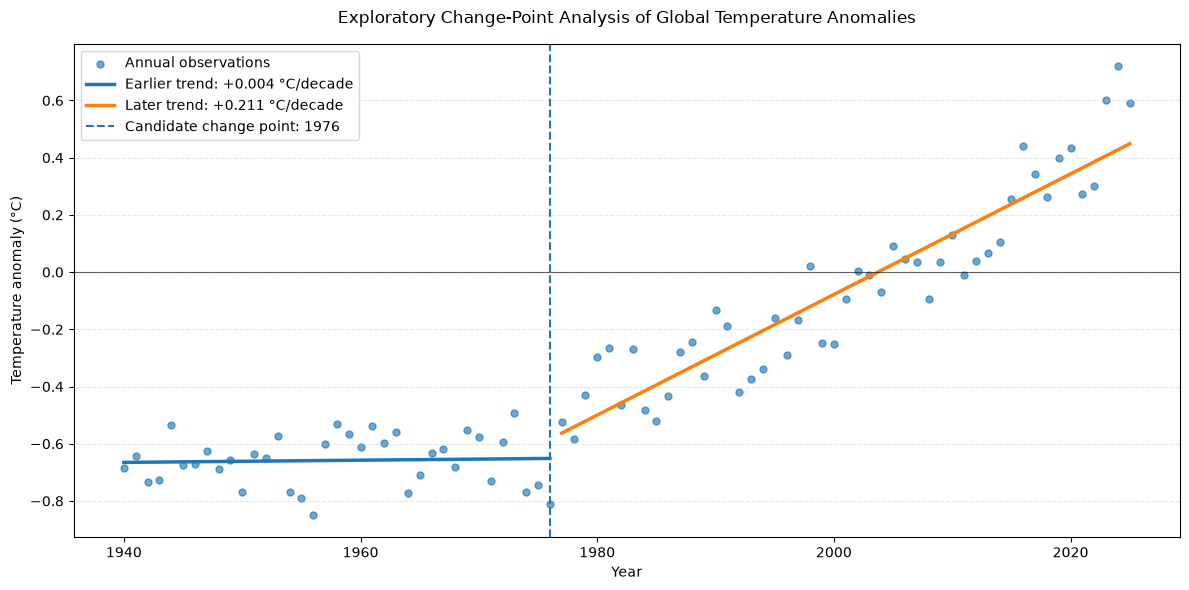

In [57]:
import matplotlib.pyplot as plt
import numpy as np

cp = int(best_change["Candidate year"])

before = change_data["year"] <= cp
after = change_data["year"] > cp

# Fit separate linear trends
fit_before = np.polyfit(
    change_data.loc[before, "year"],
    change_data.loc[before, "temperature_anomaly"],
    1
)

fit_after = np.polyfit(
    change_data.loc[after, "year"],
    change_data.loc[after, "temperature_anomaly"],
    1
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    change_data["year"],
    change_data["temperature_anomaly"],
    s=25,
    alpha=0.65,
    label="Annual observations"
)

x_before = np.linspace(
    change_data.loc[before, "year"].min(), cp, 100
)

x_after = np.linspace(
    cp + 1, change_data.loc[after, "year"].max(), 100
)

ax.plot(
    x_before,
    np.polyval(fit_before, x_before),
    linewidth=2.5,
    label=f"Earlier trend: {fit_before[0] * 10:+.3f} °C/decade"
)

ax.plot(
    x_after,
    np.polyval(fit_after, x_after),
    linewidth=2.5,
    label=f"Later trend: {fit_after[0] * 10:+.3f} °C/decade"
)

ax.axvline(
    cp,
    linestyle="--",
    linewidth=1.5,
    label=f"Candidate change point: {cp}"
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

ax.set_title(
    "Exploratory Change-Point Analysis of Global Temperature Anomalies",
    pad=15
)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature anomaly (°C)")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [58]:
# Compare a single linear trend with the two-segment change-point model

# Single linear trend
single_fit = np.polyfit(
    change_data["year"],
    change_data["temperature_anomaly"],
    1
)

single_pred = np.polyval(single_fit, change_data["year"])
single_rss = np.sum(
    (change_data["temperature_anomaly"] - single_pred) ** 2
)

# Two-segment model at the selected candidate change point
cp = int(best_change["Candidate year"])

before = change_data["year"] <= cp
after = change_data["year"] > cp

fit_before = np.polyfit(
    change_data.loc[before, "year"],
    change_data.loc[before, "temperature_anomaly"],
    1
)

fit_after = np.polyfit(
    change_data.loc[after, "year"],
    change_data.loc[after, "temperature_anomaly"],
    1
)

pred_before = np.polyval(
    fit_before, change_data.loc[before, "year"]
)

pred_after = np.polyval(
    fit_after, change_data.loc[after, "year"]
)

two_segment_rss = (
    np.sum(
        (change_data.loc[before, "temperature_anomaly"] - pred_before) ** 2
    )
    +
    np.sum(
        (change_data.loc[after, "temperature_anomaly"] - pred_after) ** 2
    )
)

# Calculate R-squared for both models
total_sum_squares = np.sum(
    (
        change_data["temperature_anomaly"]
        - change_data["temperature_anomaly"].mean()
    ) ** 2
)

single_r2 = 1 - single_rss / total_sum_squares
two_segment_r2 = 1 - two_segment_rss / total_sum_squares

print("MODEL FIT COMPARISON")
print("-" * 45)
print(f"Single-trend model RSS:       {single_rss:.4f}")
print(f"Two-segment model RSS:        {two_segment_rss:.4f}")
print(f"Single-trend model R²:        {single_r2:.4f}")
print(f"Two-segment model R²:         {two_segment_r2:.4f}")
print(
    f"RSS reduction:                "
    f"{100 * (single_rss - two_segment_rss) / single_rss:.2f}%"
)
print(
    f"R² improvement:               "
    f"{two_segment_r2 - single_r2:.4f}"
)

MODEL FIT COMPARISON
---------------------------------------------
Single-trend model RSS:       2.2531
Two-segment model RSS:        0.9828
Single-trend model R²:        0.8261
Two-segment model R²:         0.9241
RSS reduction:                56.38%
R² improvement:               0.0981


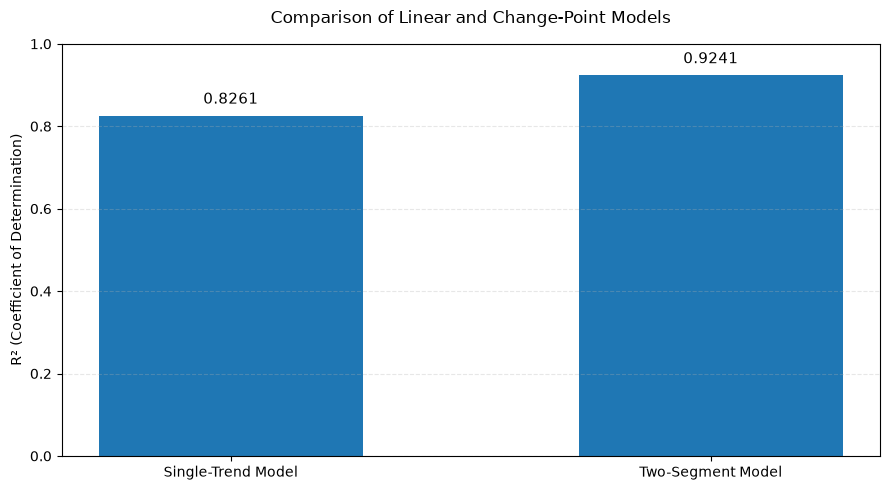

In [59]:
import matplotlib.pyplot as plt

model_names = ["Single-Trend Model", "Two-Segment Model"]
r2_values = [single_r2, two_segment_r2]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(model_names, r2_values, width=0.55)

ax.set_title("Comparison of Linear and Change-Point Models", pad=15)
ax.set_ylabel("R² (Coefficient of Determination)")
ax.set_ylim(0, 1)
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, r2_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [60]:
# Inspect the modern and paleoclimate datasets before comparison

print("MODERN TEMPERATURE DATA")
print("-" * 45)
print("Available years:", modern_global["year"].min(), "to",
      modern_global["year"].max())
print("Number of observations:", len(modern_global))
print("Temperature variable:", "temperature_anomaly")

print("\nPAGES2k PALEOCLIMATE DATA")
print("-" * 45)
print("Available years:", paleo["Year"].min(), "to",
      paleo["Year"].max())

reconstruction = paleo.dropna(subset=["Full ensemble median"])

print("Valid reconstruction years:",
      reconstruction["Year"].min(), "to",
      reconstruction["Year"].max())
print("Valid reconstruction observations:", len(reconstruction))

print("\nAvailable PAGES2k columns:")
print(paleo.columns.tolist())

MODERN TEMPERATURE DATA
---------------------------------------------
Available years: 1940 to 2025
Number of observations: 86
Temperature variable: temperature_anomaly

PAGES2k PALEOCLIMATE DATA
---------------------------------------------
Available years: 1 to 2017
Valid reconstruction years: 1 to 2000
Valid reconstruction observations: 2000

Available PAGES2k columns:
['Year', 'Cowtan & Way instrumental target', 'Full ensemble median', 'Full ensemble 2.5th percentile', 'Full ensemble 97.5th percentile', 'Cowtan & Way instrumental target 31-year filtered', '31-year filtered full ensemble median', '31-year filtered full ensemble 2.5th percentile', '31-year filtered full ensemble 97.5th percentile']


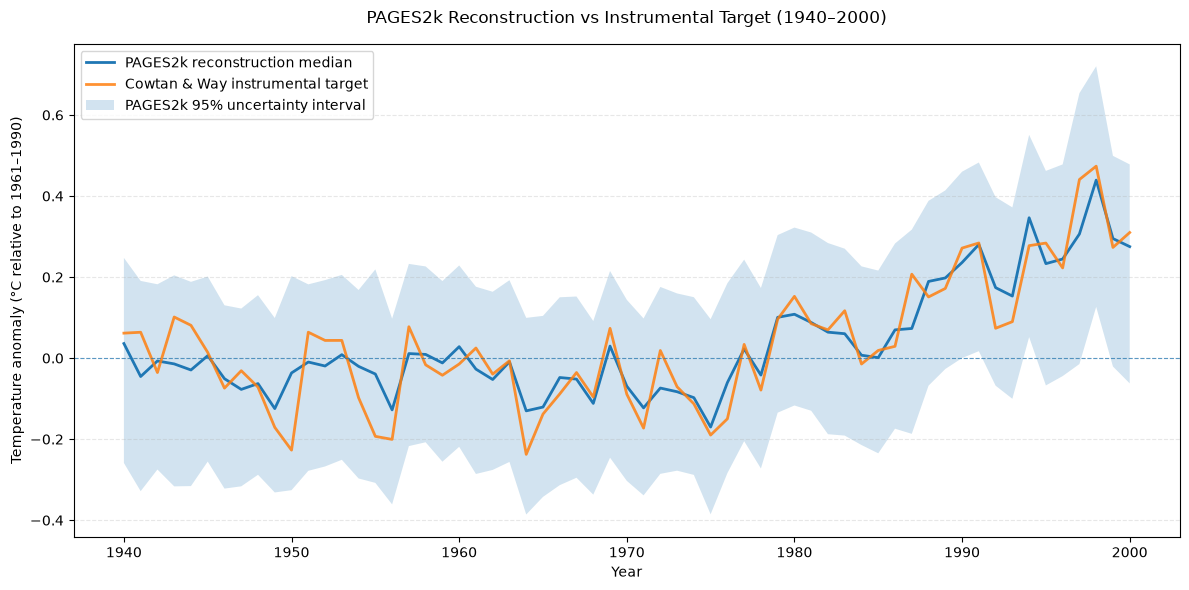

Comparison period: 1940 to 2000
Number of overlapping observations: 61


In [61]:
# Compare PAGES2k reconstruction and its instrumental target, 1940–2000

import matplotlib.pyplot as plt

overlap = paleo[
    paleo["Year"].between(1940, 2000)
].dropna(
    subset=[
        "Full ensemble median",
        "Cowtan & Way instrumental target"
    ]
).copy()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    overlap["Year"],
    overlap["Full ensemble median"],
    label="PAGES2k reconstruction median",
    linewidth=2
)

ax.plot(
    overlap["Year"],
    overlap["Cowtan & Way instrumental target"],
    label="Cowtan & Way instrumental target",
    linewidth=2,
    alpha=0.85
)

ax.fill_between(
    overlap["Year"],
    overlap["Full ensemble 2.5th percentile"],
    overlap["Full ensemble 97.5th percentile"],
    alpha=0.2,
    label="PAGES2k 95% uncertainty interval"
)

ax.axhline(0, linestyle="--", linewidth=0.8, alpha=0.7)

ax.set_title(
    "PAGES2k Reconstruction vs Instrumental Target (1940–2000)",
    pad=15
)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature anomaly (°C relative to 1961–1990)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("Comparison period:", overlap["Year"].min(), "to", overlap["Year"].max())
print("Number of overlapping observations:", len(overlap))

In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
import numpy as np

# Compare reconstruction and instrumental target
reconstruction_values = overlap["Full ensemble median"]
instrumental_values = overlap["Cowtan & Way instrumental target"]

mae = mean_absolute_error(instrumental_values, reconstruction_values)

rmse = np.sqrt(
    mean_squared_error(instrumental_values, reconstruction_values)
)

correlation, p_value = pearsonr(
    instrumental_values,
    reconstruction_values
)

print("PAGES2k RECONSTRUCTION AGREEMENT (1940–2000)")
print("-" * 50)
print(f"Number of overlapping years: {len(overlap)}")
print(f"Mean Absolute Error (MAE):   {mae:.4f} °C")
print(f"Root Mean Squared Error:     {rmse:.4f} °C")
print(f"Pearson correlation:         {correlation:.4f}")
print(f"Correlation p-value:         {p_value:.4e}")
print(f"Mean reconstruction bias:    {(reconstruction_values - instrumental_values).mean():+.4f} °C")

PAGES2k RECONSTRUCTION AGREEMENT (1940–2000)
--------------------------------------------------
Number of overlapping years: 61
Mean Absolute Error (MAE):   0.0487 °C
Root Mean Squared Error:     0.0635 °C
Pearson correlation:         0.9156
Correlation p-value:         5.1699e-25
Mean reconstruction bias:    +0.0007 °C


In [63]:
# Quantify uncertainty in the PAGES2k reconstruction

uncertainty_data = paleo.dropna(
    subset=[
        "Full ensemble median",
        "Full ensemble 2.5th percentile",
        "Full ensemble 97.5th percentile"
    ]
).copy()

uncertainty_data["Uncertainty width"] = (
    uncertainty_data["Full ensemble 97.5th percentile"]
    - uncertainty_data["Full ensemble 2.5th percentile"]
)

print("PAGES2k RECONSTRUCTION UNCERTAINTY")
print("-" * 45)
print("Valid observations:", len(uncertainty_data))
print(
    "Year range:",
    uncertainty_data["Year"].min(),
    "to",
    uncertainty_data["Year"].max()
)
print(
    f"Mean interval width:   "
    f"{uncertainty_data['Uncertainty width'].mean():.4f} °C"
)
print(
    f"Median interval width: "
    f"{uncertainty_data['Uncertainty width'].median():.4f} °C"
)
print(
    f"Minimum interval width: "
    f"{uncertainty_data['Uncertainty width'].min():.4f} °C"
)
print(
    f"Maximum interval width: "
    f"{uncertainty_data['Uncertainty width'].max():.4f} °C"
)

print("\nUNCERTAINTY BY HISTORICAL PERIOD")
print("-" * 45)

uncertainty_data["Period"] = pd.cut(
    uncertainty_data["Year"],
    bins=[0, 499, 999, 1499, 2000],
    labels=["1–499", "500–999", "1000–1499", "1500–2000"]
)

period_uncertainty = uncertainty_data.groupby(
    "Period", observed=True
)["Uncertainty width"].agg(
    ["mean", "median", "min", "max", "count"]
)

print(period_uncertainty.round(4))

PAGES2k RECONSTRUCTION UNCERTAINTY
---------------------------------------------
Valid observations: 2000
Year range: 1 to 2000
Mean interval width:   0.6463 °C
Median interval width: 0.6428 °C
Minimum interval width: 0.4284 °C
Maximum interval width: 1.1266 °C

UNCERTAINTY BY HISTORICAL PERIOD
---------------------------------------------
             mean  median     min     max  count
Period                                          
1–499      0.7418  0.7315  0.5970  1.0152    499
500–999    0.6772  0.6627  0.5411  1.1266    500
1000–1499  0.6044  0.6002  0.5109  0.7533    500
1500–2000  0.5624  0.5397  0.4284  0.8073    501


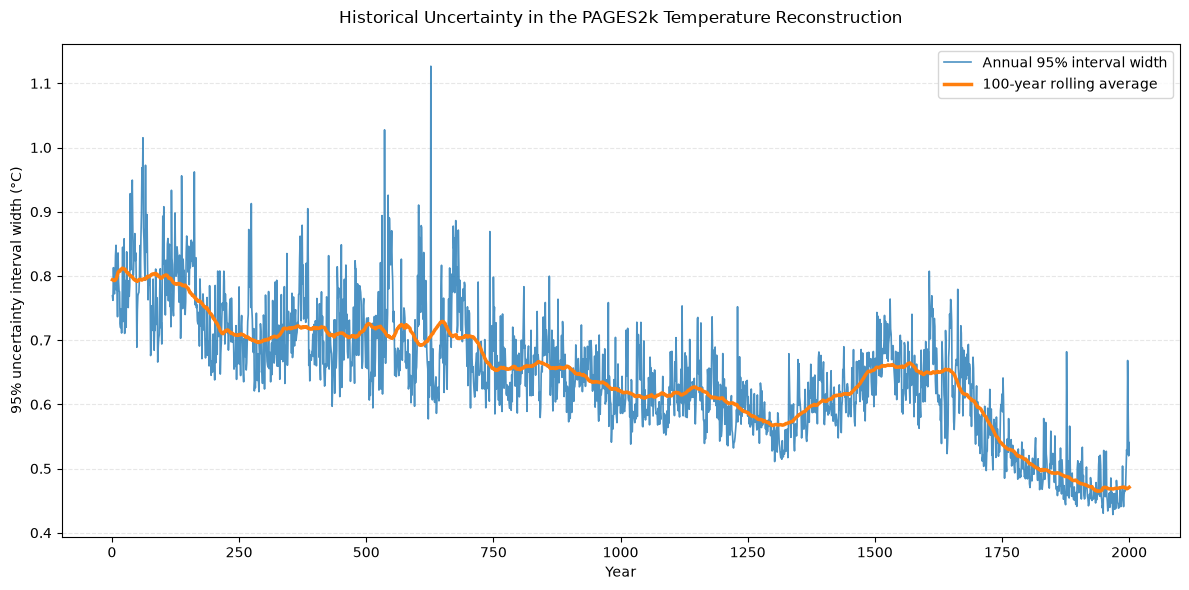

In [64]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    uncertainty_data["Year"],
    uncertainty_data["Uncertainty width"],
    linewidth=1.2,
    alpha=0.8,
    label="Annual 95% interval width"
)

# Add a 100-year rolling average to reveal the broader pattern
rolling_width = (
    uncertainty_data
    .sort_values("Year")["Uncertainty width"]
    .rolling(window=100, center=True, min_periods=50)
    .mean()
)

ax.plot(
    uncertainty_data["Year"],
    rolling_width,
    linewidth=2.5,
    label="100-year rolling average"
)

ax.set_title(
    "Historical Uncertainty in the PAGES2k Temperature Reconstruction",
    pad=15
)
ax.set_xlabel("Year")
ax.set_ylabel("95% uncertainty interval width (°C)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

A. Early historical period: greater uncertainty
During the first several centuries, the 100-year rolling average of the uncertainty interval is around 0.75–0.80°C. There are also occasional spikes above 0.9°C.
B. Middle historical period: gradual decline
The rolling average generally declines through much of the period, reaching approximately 0.57–0.62°C around the 11th–14th centuries.
C. Temporary increase around 1500–1700
The rolling average rises to approximately 0.65°C before declining again. This is an important reminder that reconstruction uncertainty does not decrease monotonically.
D. Later historical period: narrower intervals
After approximately 1700, the rolling average declines substantially, reaching roughly 0.47°C near the end of the reconstruction.

HISTORICAL TEMPERATURE SUMMARY
-------------------------------------------------------
                     mean  median     min     max     std  count
Historical period                                               
1–499             -0.1940 -0.1929 -0.3914  0.0152  0.0716    499
500–999           -0.2025 -0.1999 -0.4609  0.0512  0.0794    500
1000–1499         -0.3194 -0.3154 -0.6029 -0.0907  0.0972    500
1500–2000         -0.3479 -0.3858 -0.7128  0.4392  0.1756    501


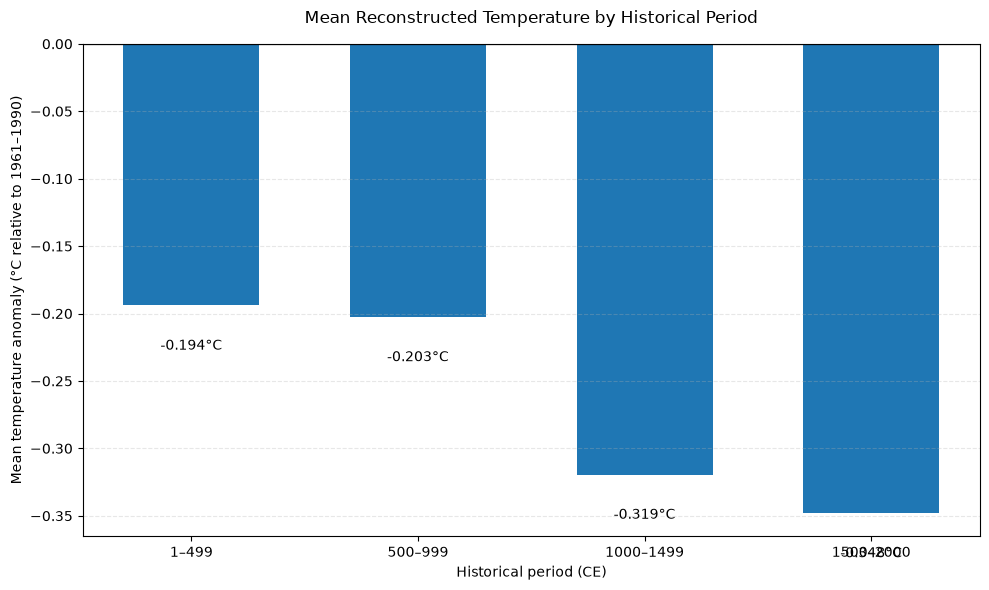

In [65]:
# Historical temperature patterns in the PAGES2k reconstruction

historical_data = paleo.dropna(
    subset=["Full ensemble median"]
).copy()

period_bins = [0, 499, 999, 1499, 2000]
period_labels = [
    "1–499",
    "500–999",
    "1000–1499",
    "1500–2000"
]

historical_data["Historical period"] = pd.cut(
    historical_data["Year"],
    bins=period_bins,
    labels=period_labels
)

historical_summary = historical_data.groupby(
    "Historical period", observed=True
)["Full ensemble median"].agg(
    ["mean", "median", "min", "max", "std", "count"]
)

print("HISTORICAL TEMPERATURE SUMMARY")
print("-" * 55)
print(historical_summary.round(4))

# Plot period averages
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    historical_summary.index.astype(str),
    historical_summary["mean"],
    width=0.6
)

ax.axhline(0, color="black", linewidth=0.9, alpha=0.7)

ax.set_title(
    "Mean Reconstructed Temperature by Historical Period",
    pad=15
)
ax.set_xlabel("Historical period (CE)")
ax.set_ylabel(
    "Mean temperature anomaly (°C relative to 1961–1990)"
)
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bar, value in zip(bars, historical_summary["mean"]):
    offset = 0.012 if value >= 0 else -0.025
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f"{value:+.3f}°C",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

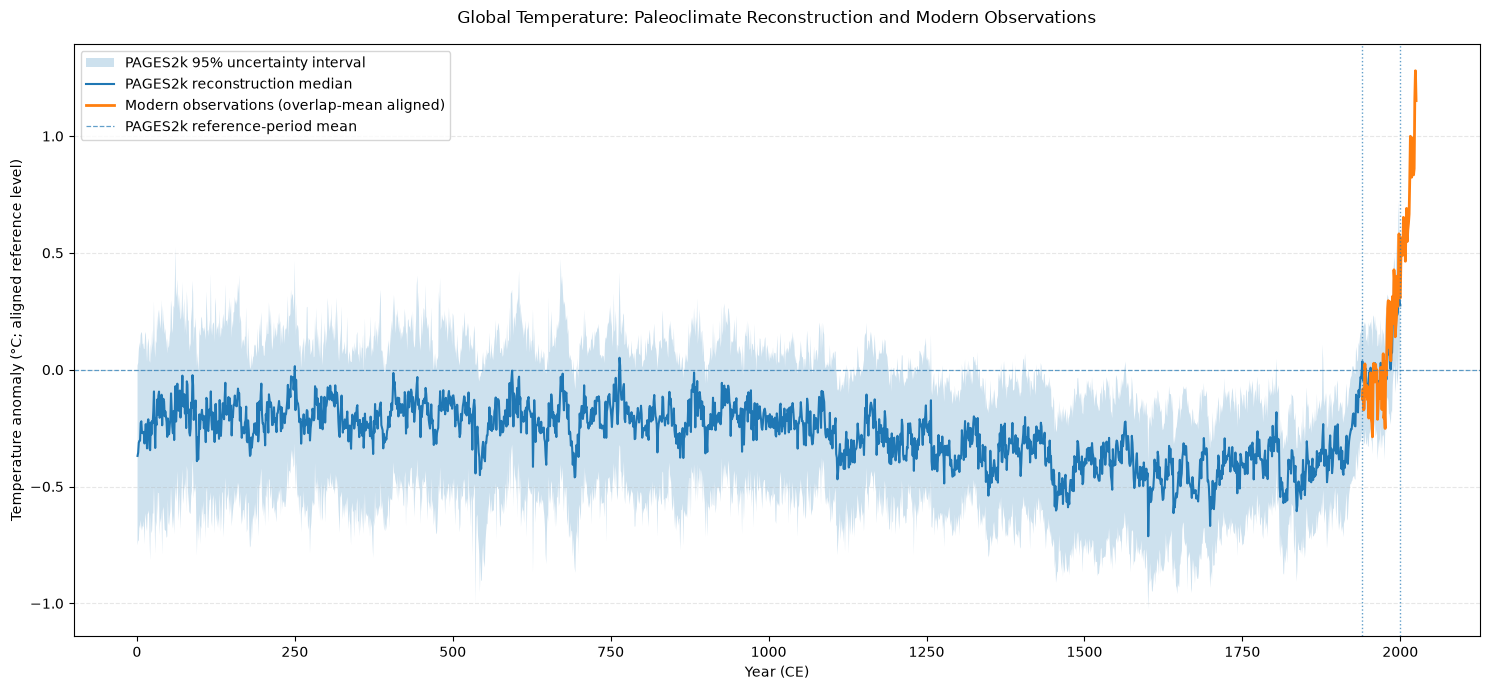

COMBINED SERIES SUMMARY
--------------------------------------------------
PAGES2k reconstruction: 1–2000
Modern observations:    1940–2025
Overlap used:           1940–2000
Matched observations:   61
Applied modern offset:  +0.5600 °C

Note: The offset aligns overlap-period means; it does not eliminate
differences in measurement, reconstruction, or uncertainty methods.


In [66]:
# FINAL COMBINED HISTORICAL-TO-MODERN TEMPERATURE GRAPH

import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare the PAGES2k reconstruction
paleo_plot = paleo.dropna(
    subset=[
        "Full ensemble median",
        "Full ensemble 2.5th percentile",
        "Full ensemble 97.5th percentile"
    ]
).sort_values("Year").copy()

# 2. Prepare modern observations
modern_plot = modern_global[
    ["year", "temperature_anomaly"]
].dropna().sort_values("year").copy()

# 3. Obtain the overlapping period: 1940–2000
overlap_paleo = paleo[
    paleo["Year"].between(1940, 2000)
].dropna(
    subset=["Cowtan & Way instrumental target"]
).copy()

overlap_modern = modern_plot[
    modern_plot["year"].between(1940, 2000)
].copy()

# Match years explicitly
matched = overlap_modern.merge(
    overlap_paleo[
        ["Year", "Cowtan & Way instrumental target"]
    ],
    left_on="year",
    right_on="Year",
    how="inner"
).dropna(
    subset=[
        "temperature_anomaly",
        "Cowtan & Way instrumental target"
    ]
)

# 4. Calculate a constant offset using overlap-period means
baseline_offset = (
    matched["Cowtan & Way instrumental target"].mean()
    - matched["temperature_anomaly"].mean()
)

modern_plot["aligned_anomaly"] = (
    modern_plot["temperature_anomaly"] + baseline_offset
)

# 5. Plot the historical reconstruction and aligned modern observations
fig, ax = plt.subplots(figsize=(15, 7))

ax.fill_between(
    paleo_plot["Year"],
    paleo_plot["Full ensemble 2.5th percentile"],
    paleo_plot["Full ensemble 97.5th percentile"],
    alpha=0.22,
    label="PAGES2k 95% uncertainty interval"
)

ax.plot(
    paleo_plot["Year"],
    paleo_plot["Full ensemble median"],
    linewidth=1.5,
    label="PAGES2k reconstruction median"
)

ax.plot(
    modern_plot["year"],
    modern_plot["aligned_anomaly"],
    linewidth=2.0,
    label="Modern observations (overlap-mean aligned)"
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=0.9,
    alpha=0.7,
    label="PAGES2k reference-period mean"
)

ax.axvline(
    1940,
    linestyle=":",
    linewidth=1,
    alpha=0.7
)

ax.axvline(
    2000,
    linestyle=":",
    linewidth=1,
    alpha=0.7
)

ax.set_title(
    "Global Temperature: Paleoclimate Reconstruction and Modern Observations",
    pad=15
)
ax.set_xlabel("Year (CE)")
ax.set_ylabel("Temperature anomaly (°C; aligned reference level)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

print("COMBINED SERIES SUMMARY")
print("-" * 50)
print(f"PAGES2k reconstruction: {paleo_plot['Year'].min()}–{paleo_plot['Year'].max()}")
print(f"Modern observations:    {modern_plot['year'].min()}–{modern_plot['year'].max()}")
print(f"Overlap used:           {matched['year'].min()}–{matched['year'].max()}")
print(f"Matched observations:   {len(matched)}")
print(f"Applied modern offset:  {baseline_offset:+.4f} °C")
print("\nNote: The offset aligns overlap-period means; it does not eliminate")
print("differences in measurement, reconstruction, or uncertainty methods.")

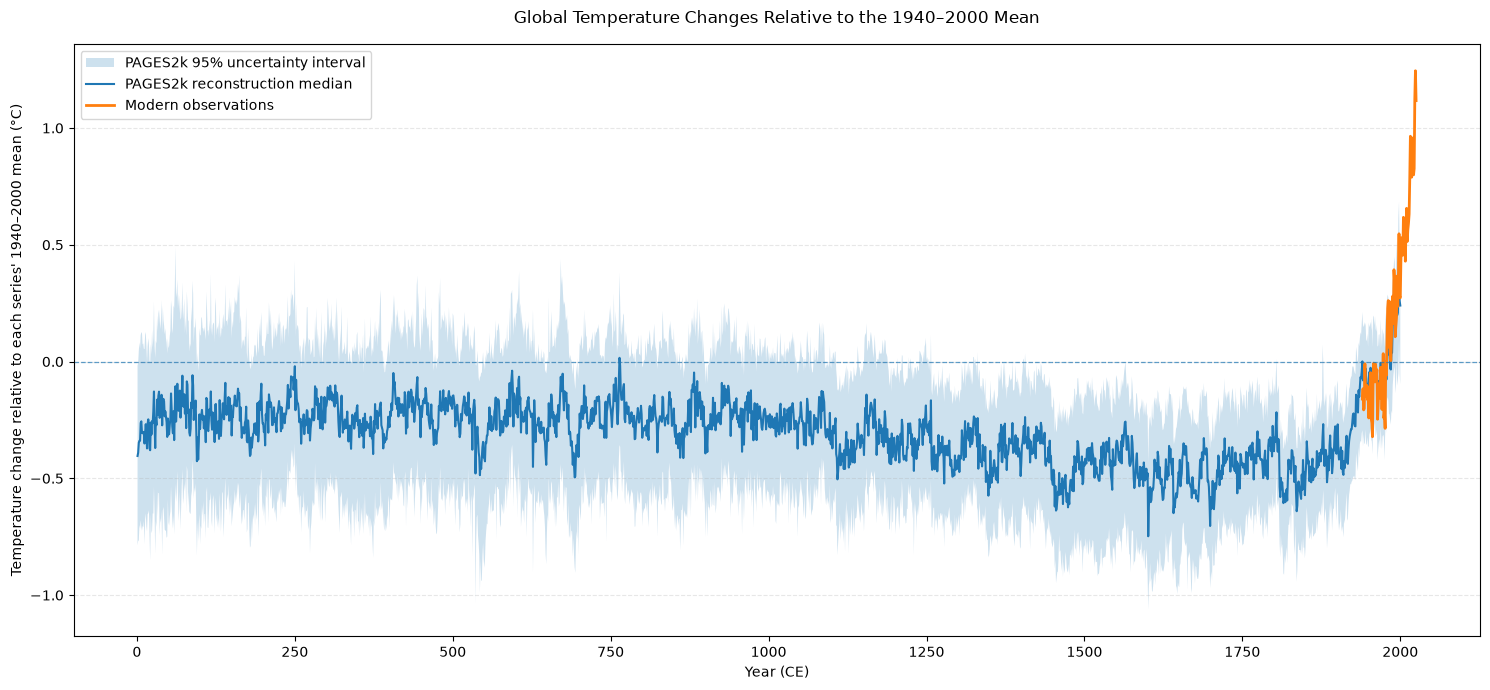

BASELINE ALIGNMENT
---------------------------------------------
PAGES2k overlap mean: +0.0352 °C
Modern overlap mean:  -0.5256 °C
Both series are now expressed as changes relative to their own overlap-period means.
This aligns the reference levels for visualization, not the underlying methods.


In [67]:
# FINAL BASELINE-ALIGNED COMPARISON
# Each series is expressed relative to its own 1940–2000 mean.

import matplotlib.pyplot as plt

# Historical reconstruction
paleo_plot = paleo.dropna(
    subset=[
        "Full ensemble median",
        "Full ensemble 2.5th percentile",
        "Full ensemble 97.5th percentile"
    ]
).sort_values("Year").copy()

# Modern observations
modern_plot = modern_global[
    ["year", "temperature_anomaly"]
].dropna().sort_values("year").copy()

# Calculate each series' mean during 1940–2000
paleo_overlap = paleo_plot[
    paleo_plot["Year"].between(1940, 2000)
]

modern_overlap = modern_plot[
    modern_plot["year"].between(1940, 2000)
]

paleo_reference_mean = paleo_overlap["Full ensemble median"].mean()
modern_reference_mean = modern_overlap["temperature_anomaly"].mean()

# Express both series as deviations from their own overlap-period means
paleo_plot["relative_anomaly"] = (
    paleo_plot["Full ensemble median"] - paleo_reference_mean
)
paleo_plot["relative_lower"] = (
    paleo_plot["Full ensemble 2.5th percentile"] - paleo_reference_mean
)
paleo_plot["relative_upper"] = (
    paleo_plot["Full ensemble 97.5th percentile"] - paleo_reference_mean
)

modern_plot["relative_anomaly"] = (
    modern_plot["temperature_anomaly"] - modern_reference_mean
)

# Plot
fig, ax = plt.subplots(figsize=(15, 7))

ax.fill_between(
    paleo_plot["Year"],
    paleo_plot["relative_lower"],
    paleo_plot["relative_upper"],
    alpha=0.22,
    label="PAGES2k 95% uncertainty interval"
)

ax.plot(
    paleo_plot["Year"],
    paleo_plot["relative_anomaly"],
    linewidth=1.5,
    label="PAGES2k reconstruction median"
)

ax.plot(
    modern_plot["year"],
    modern_plot["relative_anomaly"],
    linewidth=2,
    label="Modern observations"
)

ax.axhline(0, linestyle="--", linewidth=0.9, alpha=0.7)

ax.set_title(
    "Global Temperature Changes Relative to the 1940–2000 Mean",
    pad=15
)
ax.set_xlabel("Year (CE)")
ax.set_ylabel("Temperature change relative to each series' 1940–2000 mean (°C)")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("BASELINE ALIGNMENT")
print("-" * 45)
print(f"PAGES2k overlap mean: {paleo_reference_mean:+.4f} °C")
print(f"Modern overlap mean:  {modern_reference_mean:+.4f} °C")
print("Both series are now expressed as changes relative to their own overlap-period means.")
print("This aligns the reference levels for visualization, not the underlying methods.")
